In [3]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

loan_df = pd.read_csv("../Data/Loan_Default.csv")

loan_df.head()

,ID,year,loan_limit,Gender,approv_in_adv,loan_type,loan_purpose,Credit_Worthiness,open_credit,business_or_commercial,...,credit_type,Credit_Score,co-applicant_credit_type,age,submission_of_application,LTV,Region,Security_Type,Status,dtir1
0,24890,2019,cf,Sex Not Available,nopre,type1,p1,l1,nopc,nob/c,...,EXP,758,CIB,25-34,to_inst,98.728814,south,direct,1,45.0
1,24891,2019,cf,Male,nopre,type2,p1,l1,nopc,b/c,...,EQUI,552,EXP,55-64,to_inst,NaN,North,direct,1,NaN
2,24892,2019,cf,Male,pre,type1,p1,l1,nopc,nob/c,...,EXP,834,CIB,35-44,to_inst,80.019685,south,direct,0,46.0
3,24893,2019,cf,Male,nopre,type1,p4,l1,nopc,nob/c,...,EXP,587,CIB,45-54,not_inst,69.376900,North,direct,0,42.0
4,24894,2019,cf,Joint,pre,type1,p1,l1,nopc,nob/c,...,CRIF,602,EXP,25-34,not_inst,91.886544,North,direct,0,39.0


In [4]:
loan_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 148670 entries, 0 to 148669
Data columns (total 34 columns):
 #   Column                     Non-Null Count   Dtype  
---  ------                     --------------   -----  
 0   ID                         148670 non-null  int64  
 1   year                       148670 non-null  int64  
 2   loan_limit                 145326 non-null  object 
 3   Gender                     148670 non-null  object 
 4   approv_in_adv              147762 non-null  object 
 5   loan_type                  148670 non-null  object 
 6   loan_purpose               148536 non-null  object 
 7   Credit_Worthiness          148670 non-null  object 
 8   open_credit                148670 non-null  object 
 9   business_or_commercial     148670 non-null  object 
 10  loan_amount                148670 non-null  int64  
 11  rate_of_interest           112231 non-null  float64
 12  Interest_rate_spread       112031 non-null  float64
 13  Upfront_charges            10

## Defining A Target

In [5]:
loan_df["Status"].value_counts()

Status
0    112031
1     36639
Name: count, dtype: int64

<Axes: ylabel='Frequency'>

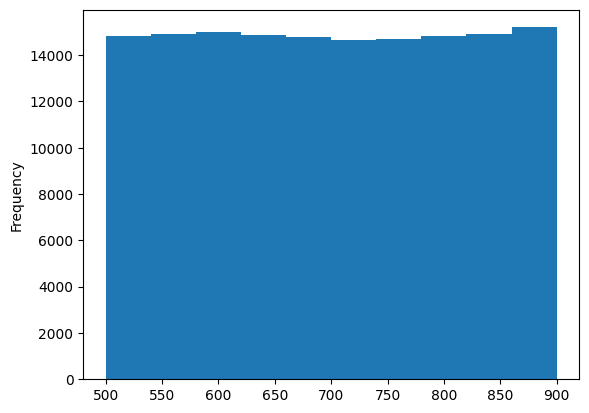

In [6]:
loan_df["Credit_Score"].plot.hist()

In [7]:
# numeric cutoff
loan_df["Fake_Target"] = np.where(loan_df["Credit_Score"] < 580, 1, 0)

loan_df["Fake_Target"].value_counts()

Fake_Target
0    118933
1     29737
Name: count, dtype: int64

In [8]:
loan_df["loan_type"].value_counts()

loan_type
type1    113173
type2     20762
type3     14735
Name: count, dtype: int64

In [9]:
# category mapping

loan_df["Fake_Target"] = (
    loan_df["loan_type"].map(
        {"type1": 0,
         "type2": 1,
         "type3": 1
        }
    )
)

loan_df["Fake_Target"].value_counts()


loan_df = loan_df.drop("Fake_Target", axis=1)

## Exploring The Target

<Axes: xlabel='Status'>

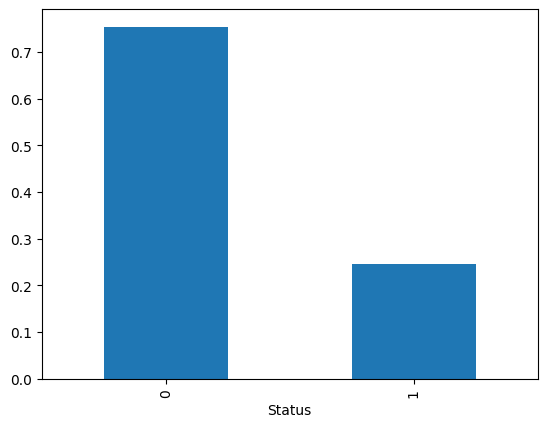

In [10]:
loan_df["Status"].value_counts(normalize=True).plot.bar()

## Exploring The Features

In [9]:
loan_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 148670 entries, 0 to 148669
Data columns (total 34 columns):
 #   Column                     Non-Null Count   Dtype  
---  ------                     --------------   -----  
 0   ID                         148670 non-null  int64  
 1   year                       148670 non-null  int64  
 2   loan_limit                 145326 non-null  object 
 3   Gender                     148670 non-null  object 
 4   approv_in_adv              147762 non-null  object 
 5   loan_type                  148670 non-null  object 
 6   loan_purpose               148536 non-null  object 
 7   Credit_Worthiness          148670 non-null  object 
 8   open_credit                148670 non-null  object 
 9   business_or_commercial     148670 non-null  object 
 10  loan_amount                148670 non-null  int64  
 11  rate_of_interest           112231 non-null  float64
 12  Interest_rate_spread       112031 non-null  float64
 13  Upfront_charges            10

<Axes: ylabel='Frequency'>

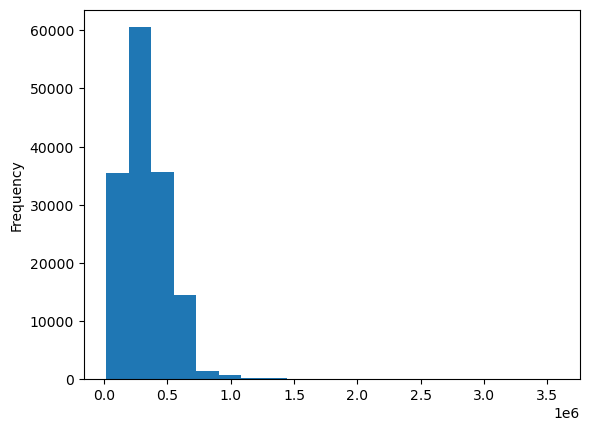

In [10]:
# numeric

loan_df["loan_amount"].plot.hist(bins=20)

<Axes: ylabel='loan_amount'>

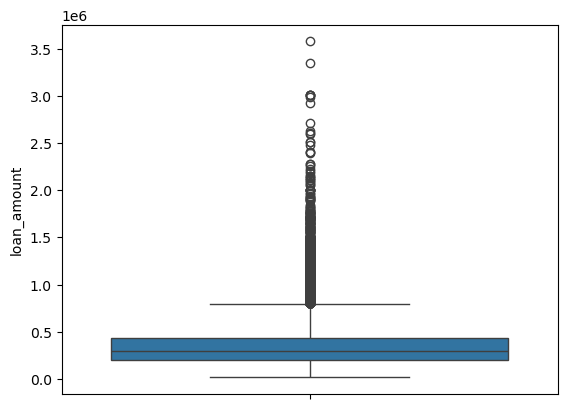

In [11]:
import seaborn as sns

sns.boxplot(loan_df["loan_amount"])

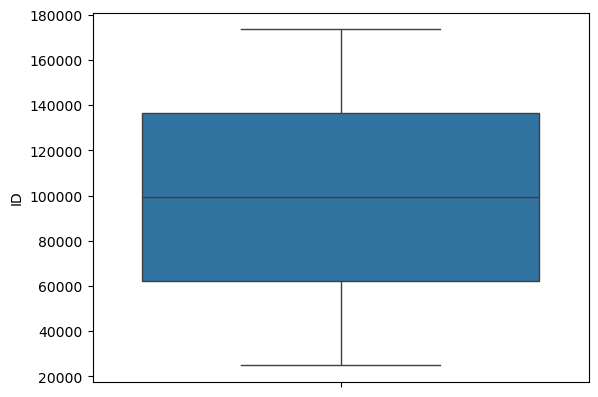

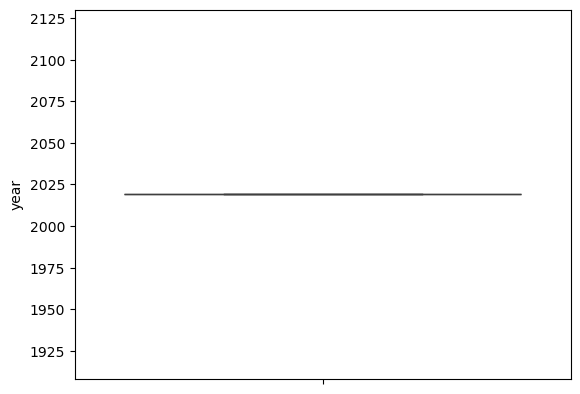

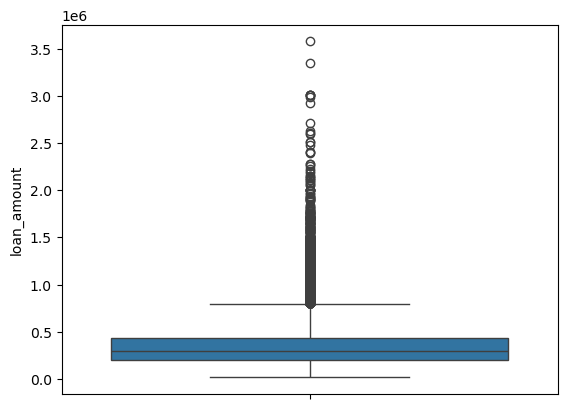

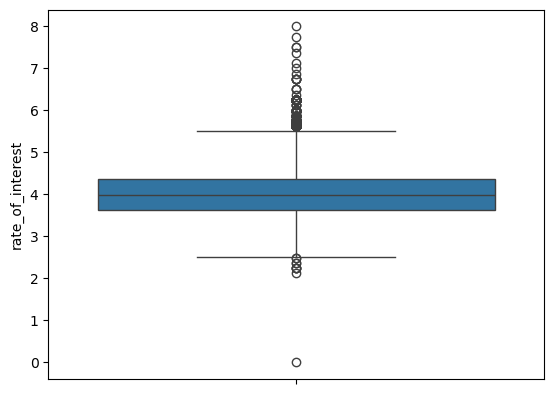

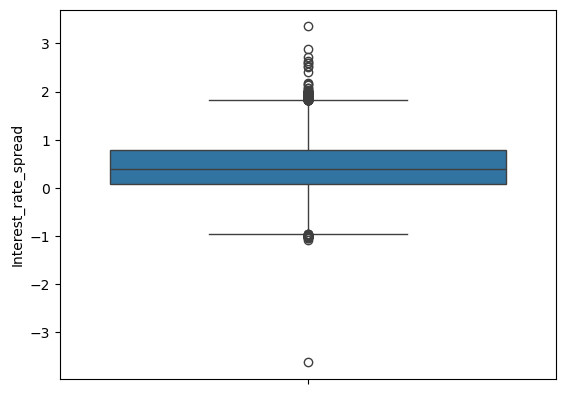

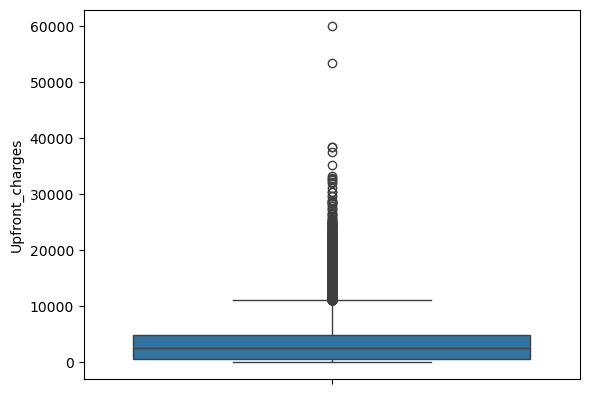

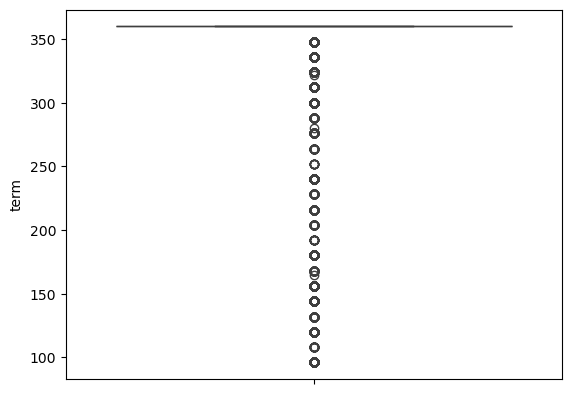

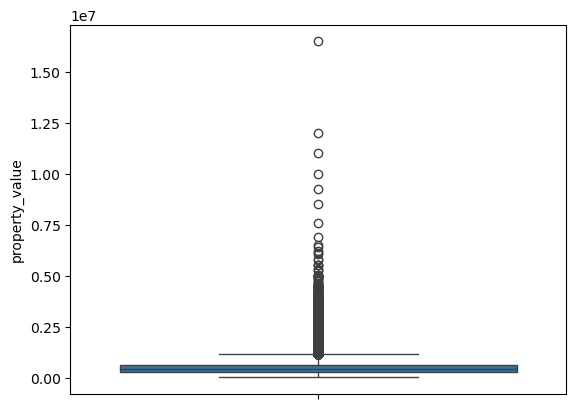

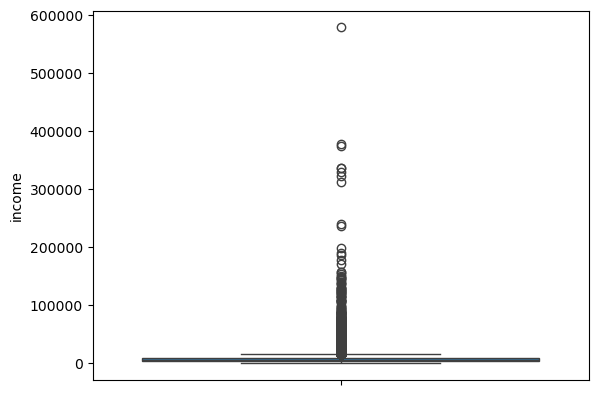

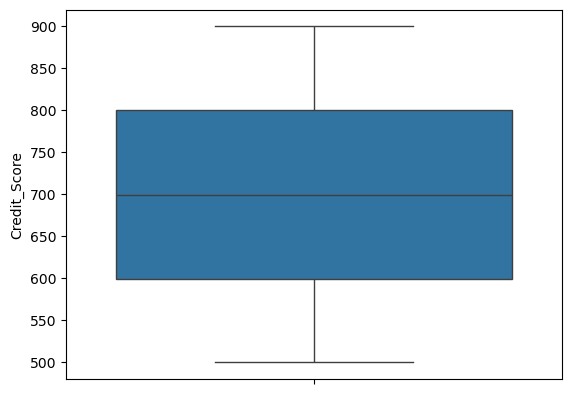

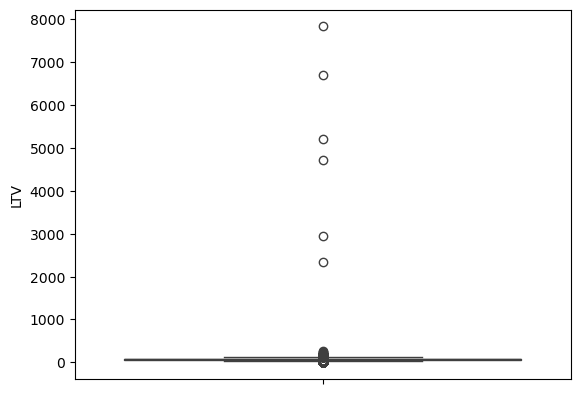

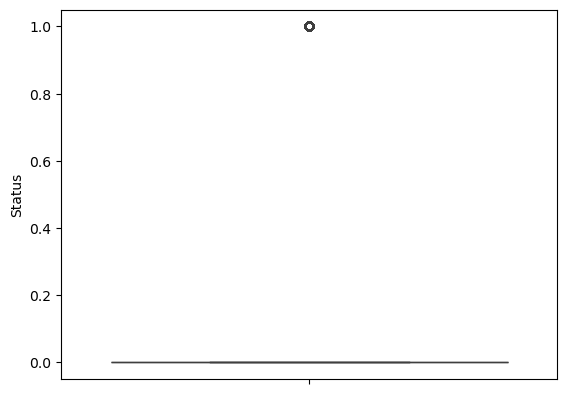

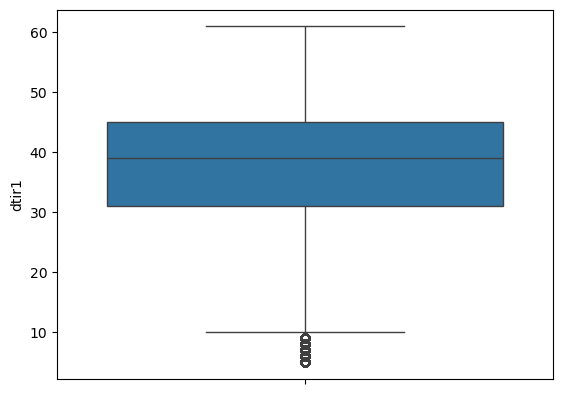

In [12]:
import matplotlib.pyplot as plt

# select numeric dtype columns and plot vs target

for column in loan_df.select_dtypes("number").columns:
    sns.boxplot(loan_df[column]).set(ylabel=column)
    plt.show()

<Axes: xlabel='Gender'>

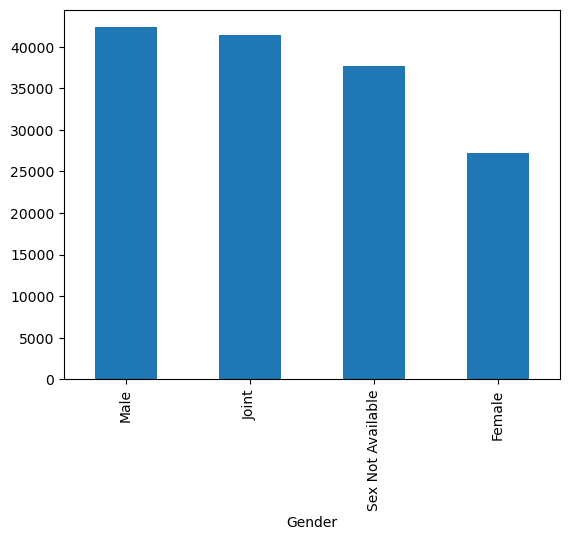

In [13]:
loan_df["Gender"].value_counts().plot.bar()

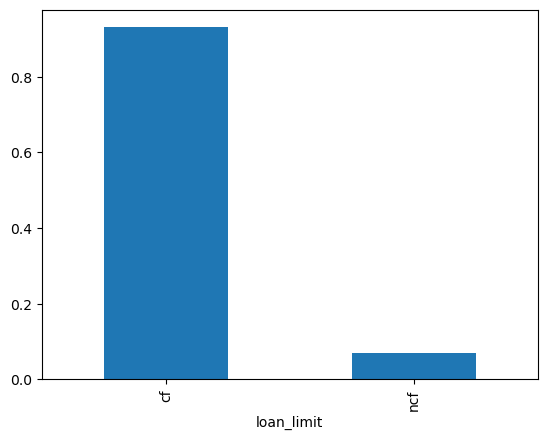

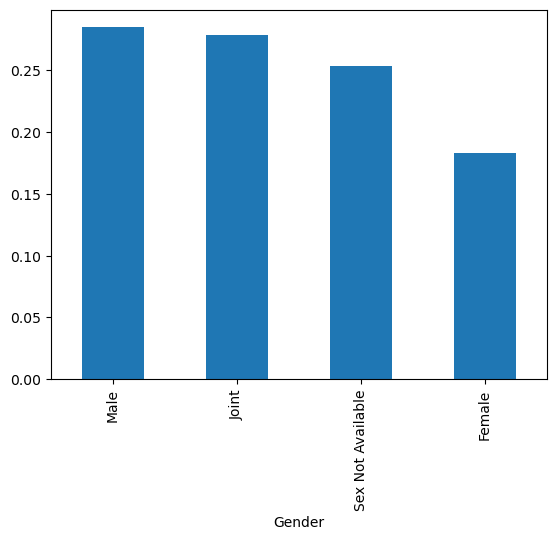

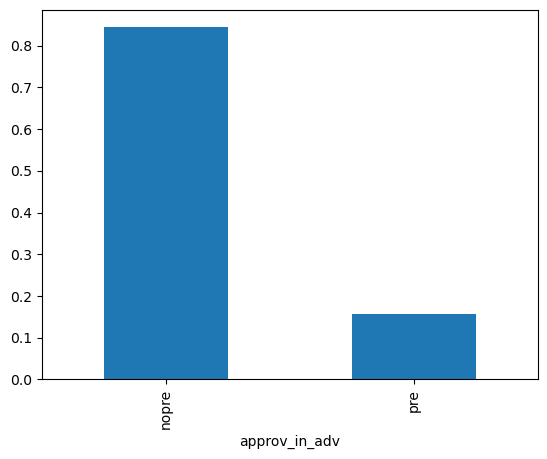

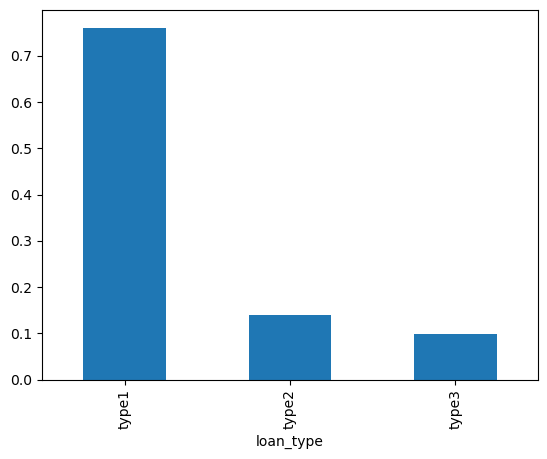

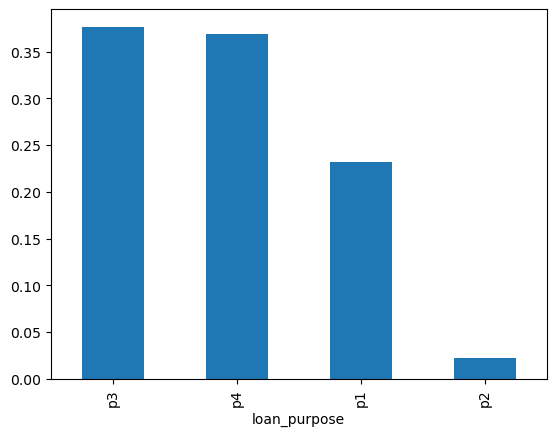

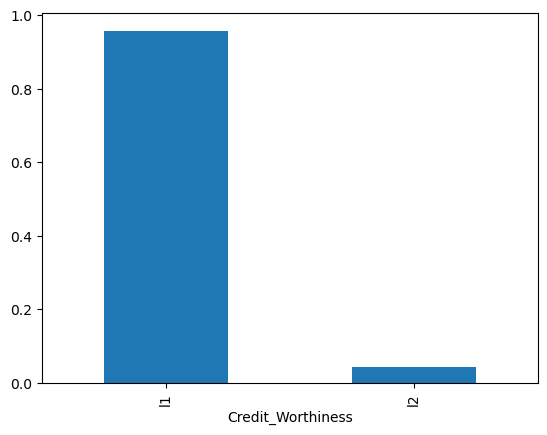

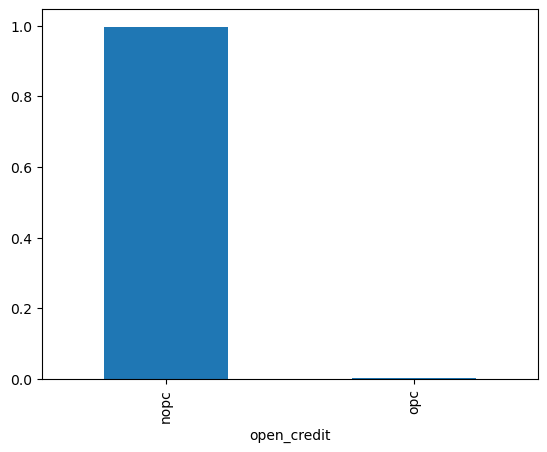

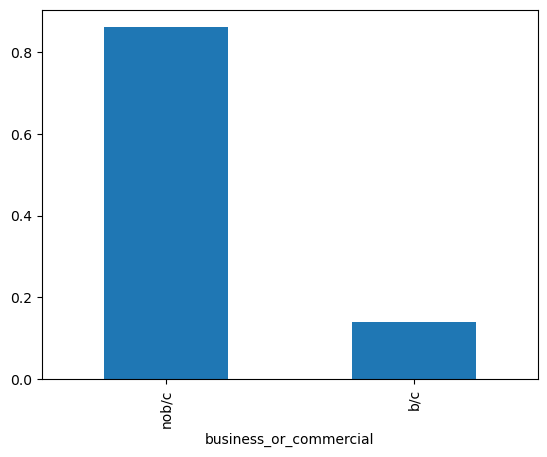

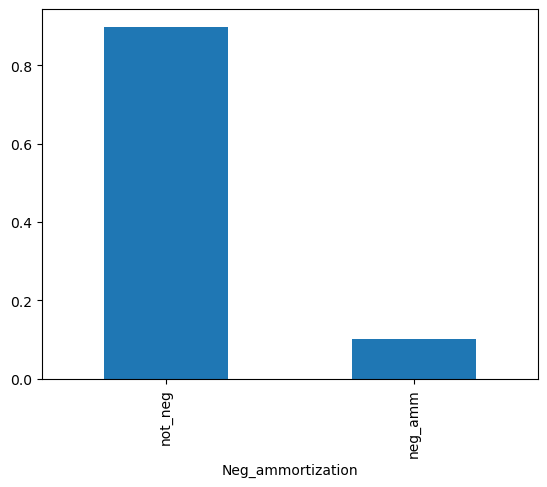

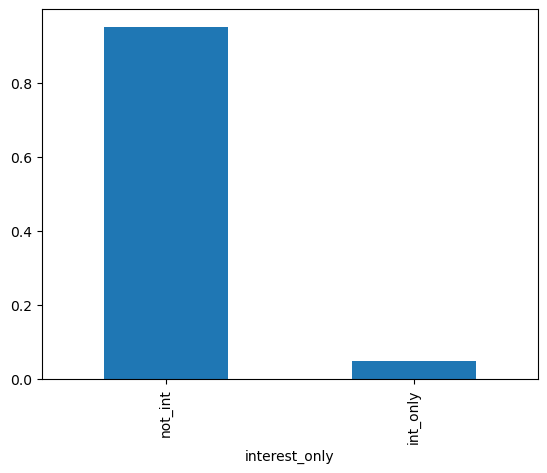

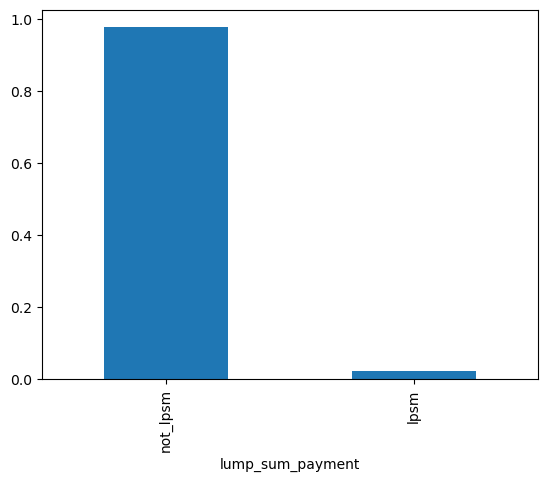

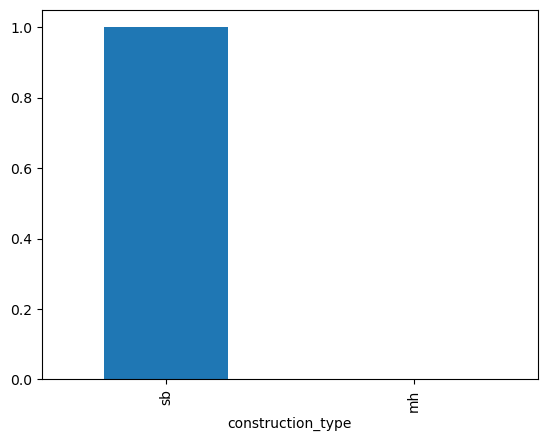

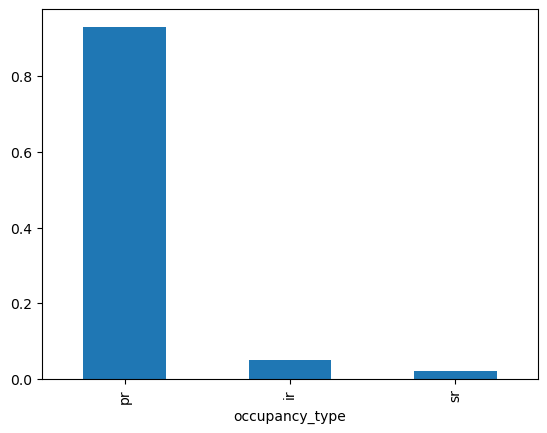

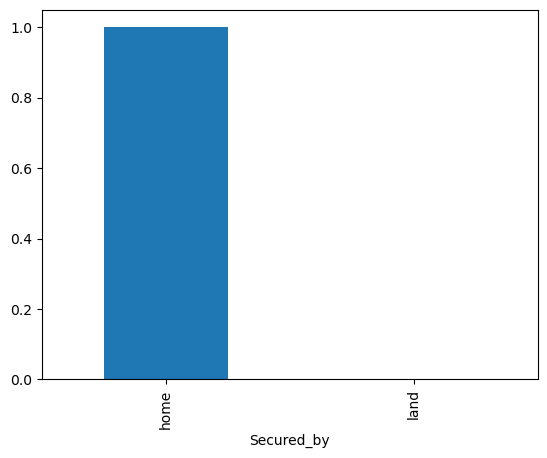

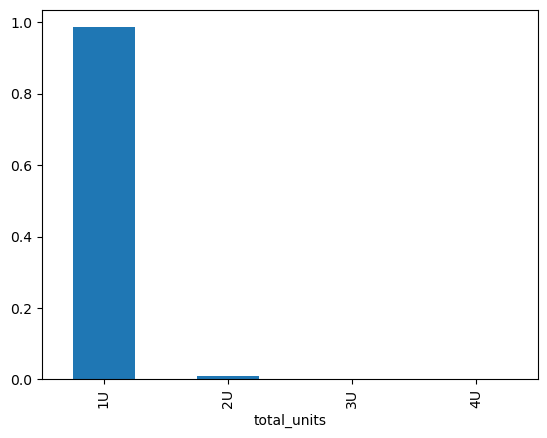

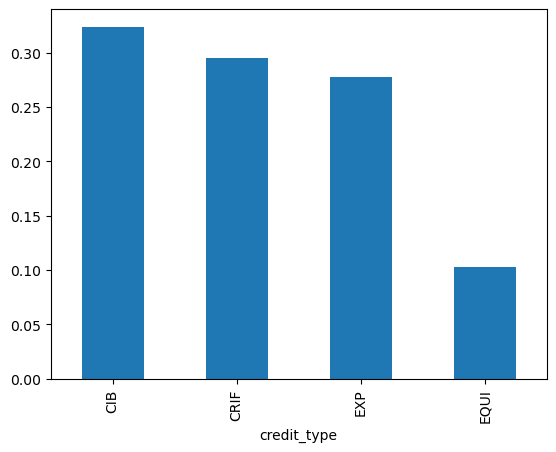

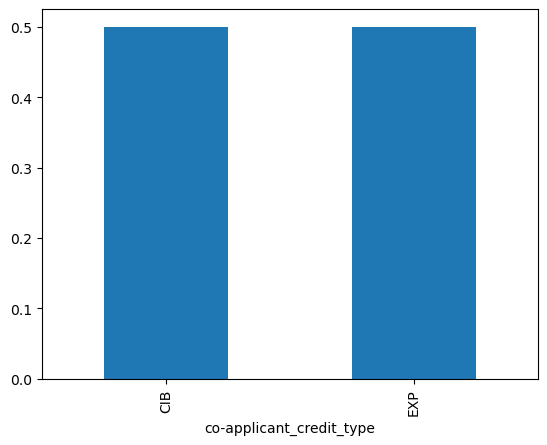

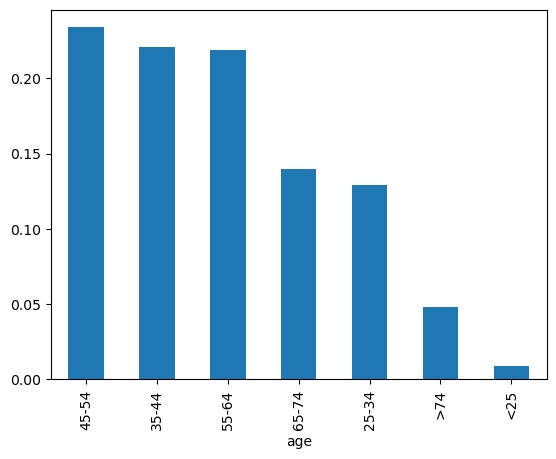

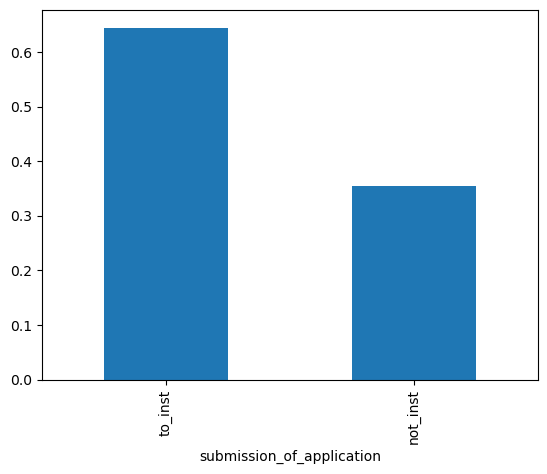

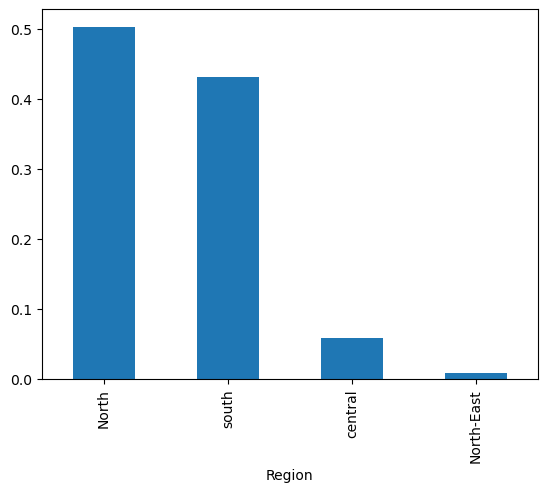

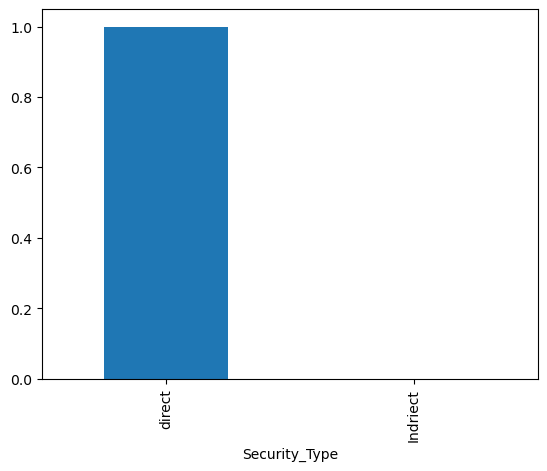

In [14]:
# select object dtype columns and plot vs target

for column in loan_df.select_dtypes("object").columns:
    loan_df[column].value_counts(normalize=True).plot.bar()
    plt.show()

## Correlation

In [15]:
loan_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 148670 entries, 0 to 148669
Data columns (total 34 columns):
 #   Column                     Non-Null Count   Dtype  
---  ------                     --------------   -----  
 0   ID                         148670 non-null  int64  
 1   year                       148670 non-null  int64  
 2   loan_limit                 145326 non-null  object 
 3   Gender                     148670 non-null  object 
 4   approv_in_adv              147762 non-null  object 
 5   loan_type                  148670 non-null  object 
 6   loan_purpose               148536 non-null  object 
 7   Credit_Worthiness          148670 non-null  object 
 8   open_credit                148670 non-null  object 
 9   business_or_commercial     148670 non-null  object 
 10  loan_amount                148670 non-null  int64  
 11  rate_of_interest           112231 non-null  float64
 12  Interest_rate_spread       112031 non-null  float64
 13  Upfront_charges            10

<Axes: xlabel='loan_amount', ylabel='property_value'>

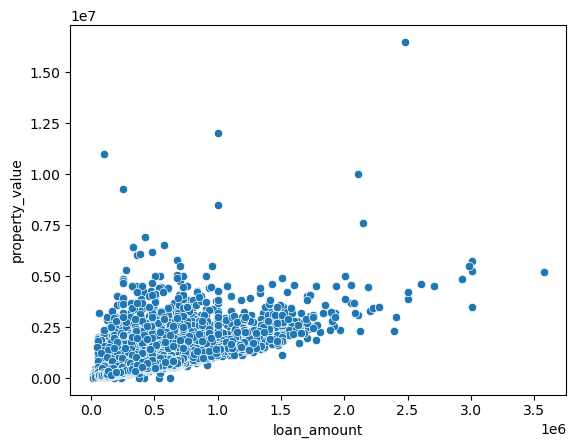

In [16]:
sns.scatterplot(loan_df, x="loan_amount", y="property_value")

In [17]:
loan_df["loan_amount"].corr(loan_df["property_value"])

0.7342490169595312

<Axes: xlabel='loan_amount', ylabel='Status'>

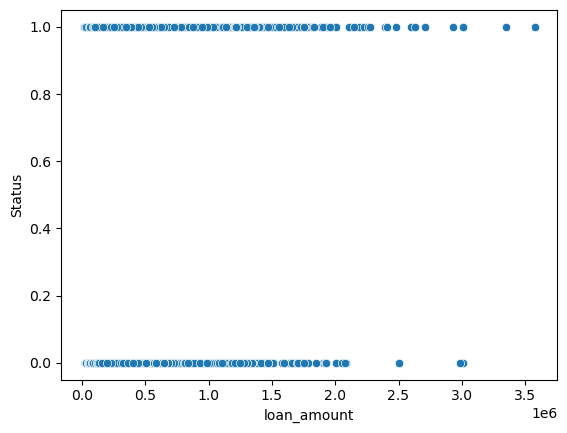

In [18]:
sns.scatterplot(loan_df, x="loan_amount", y="Status")

In [19]:
loan_df["loan_amount"].corr(loan_df["Status"])

-0.036825275544374515

In [20]:
loan_df.corr(numeric_only=True)

,ID,year,loan_amount,rate_of_interest,Interest_rate_spread,Upfront_charges,term,property_value,income,Credit_Score,LTV,Status,dtir1
ID,1.000000,NaN,-0.000566,0.000442,0.002338,-0.005507,-0.004056,0.000990,0.002535,-0.001036,-0.005853,0.001703,-0.008132
year,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
loan_amount,-0.000566,NaN,1.000000,-0.150844,-0.377272,0.065556,0.174474,0.734249,0.456065,0.004438,0.038869,-0.036825,0.015029
rate_of_interest,0.000442,NaN,-0.150844,1.000000,0.614908,-0.076473,0.209330,-0.122613,-0.041809,-0.001331,-0.000220,0.022957,0.055124
Interest_rate_spread,0.002338,NaN,-0.377272,0.614908,1.000000,0.033037,-0.157139,-0.334571,-0.151333,-0.001738,0.040257,NaN,0.078178
Upfront_charges,-0.005507,NaN,0.065556,-0.076473,0.033037,1.000000,-0.054960,0.053043,0.016580,-0.001484,-0.031347,-0.019138,0.000115
term,-0.004056,NaN,0.174474,0.209330,-0.157139,-0.054960,1.000000,0.045117,-0.053785,-0.003149,0.106834,-0.000240,0.110572
property_value,0.000990,NaN,0.734249,-0.122613,-0.334571,0.053043,0.045117,1.000000,0.414883,0.002430,-0.215102,-0.048864,-0.056288
income,0.002535,NaN,0.456065,-0.041809,-0.151333,0.016580,-0.053785,0.414883,1.000000,0.000802,-0.066203,-0.065119,-0.267807
Credit_Score,-0.001036,NaN,0.004438,-0.001331,-0.001738,-0.001484,-0.003149,0.002430,0.000802,1.000000,-0.005533,0.004004,-0.000313


<Axes: >

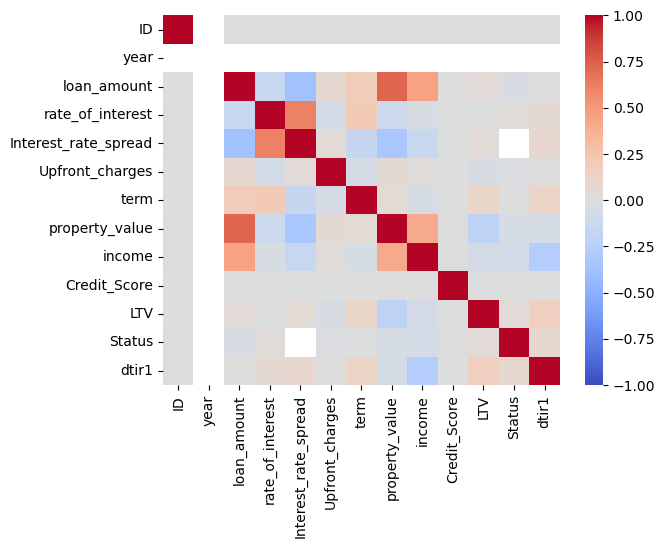

In [21]:
sns.heatmap(
    loan_df.corr(numeric_only=True),
    vmin=-1,
    vmax=1,
    cmap="coolwarm"
)

## Feature Target Relationships

<Axes: xlabel='Status', ylabel='loan_amount'>

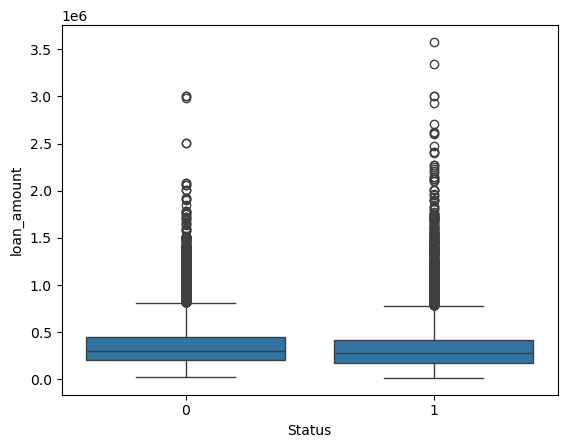

In [22]:
sns.boxplot(loan_df, x="Status", y="loan_amount")

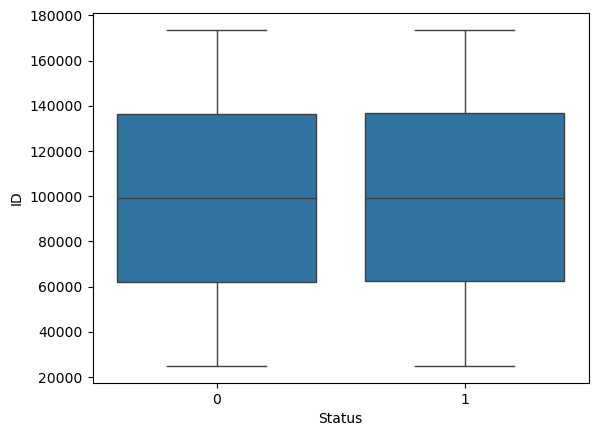

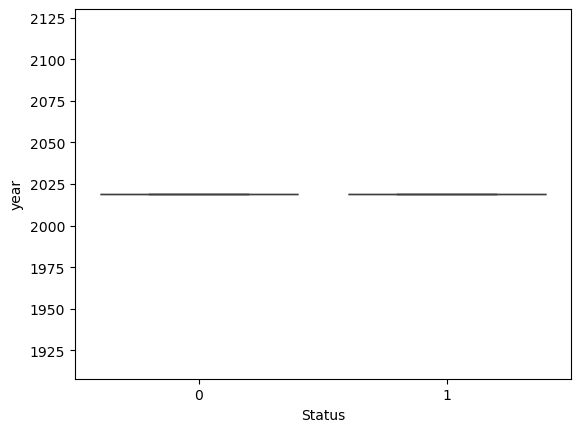

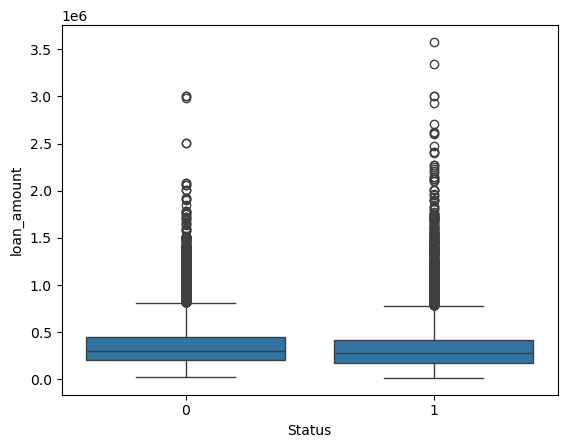

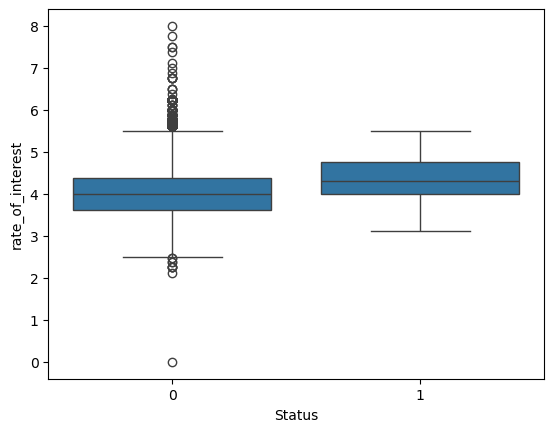

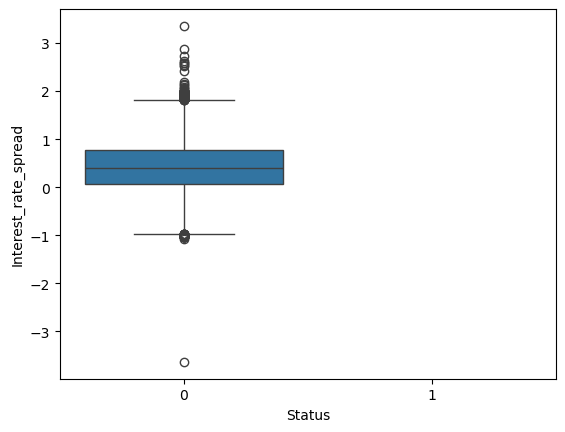

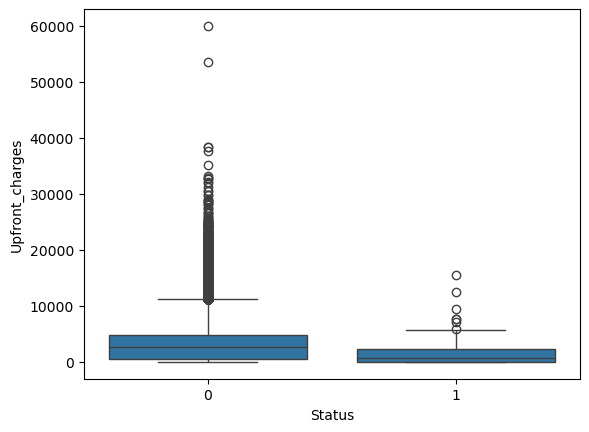

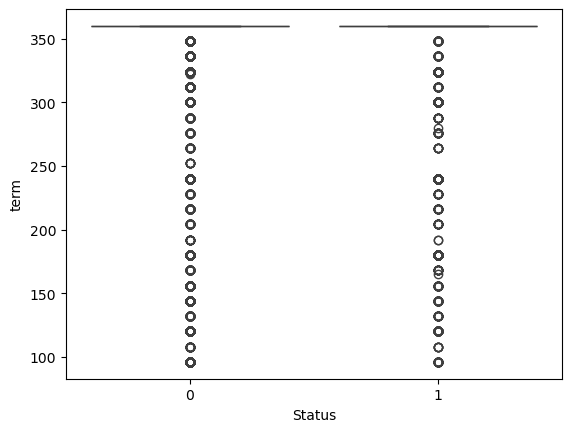

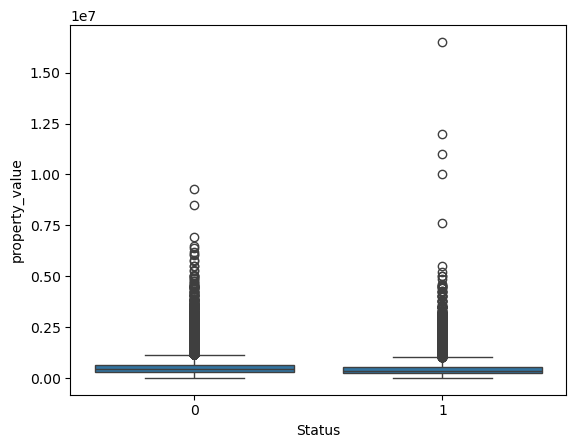

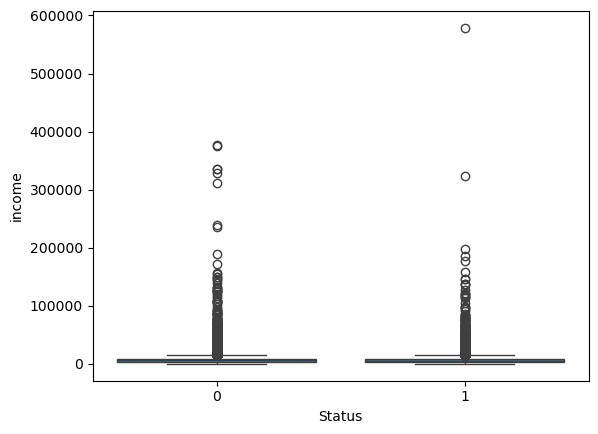

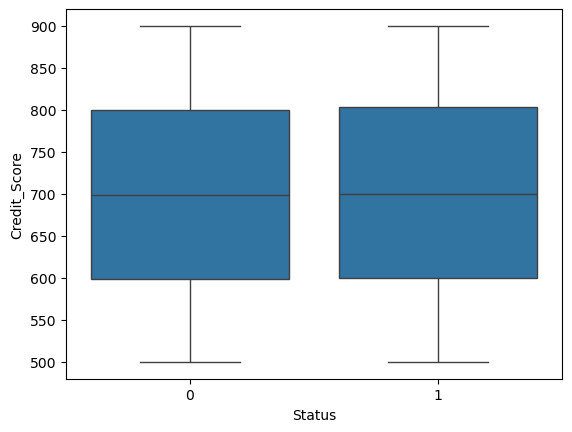

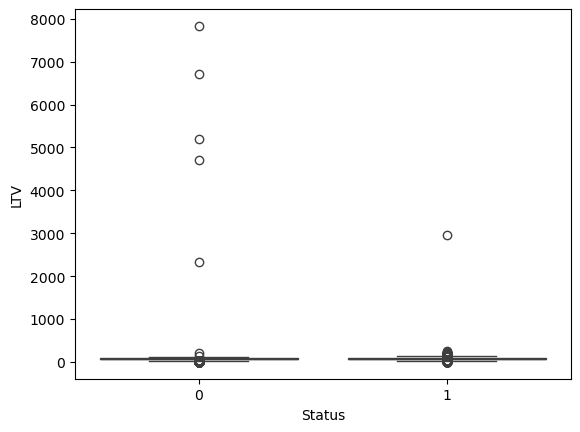

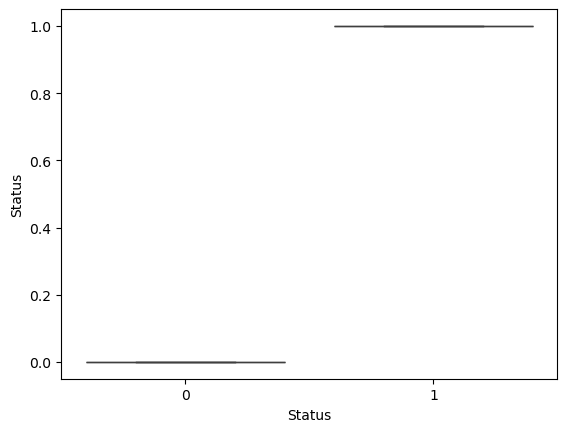

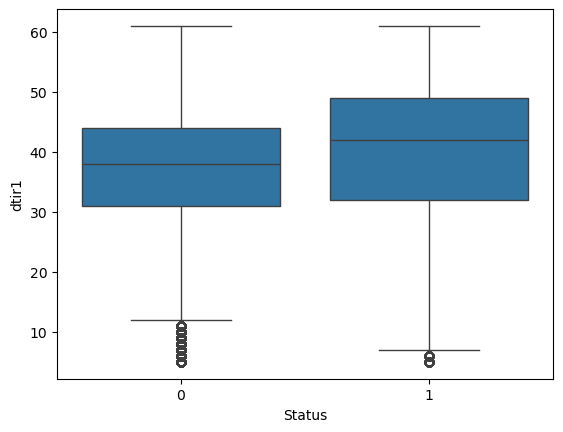

In [23]:
def box_target_plotter(data, target):
    for col in data.select_dtypes("number"):
        sns.boxplot(data=data, x=target, y=col)
        plt.show()
        
box_target_plotter(loan_df, "Status")

<Axes: xlabel='loan_amount', ylabel='Percent'>

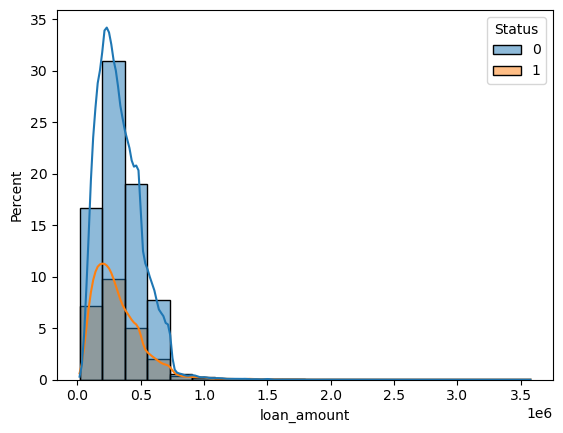

In [24]:
sns.histplot(loan_df, x="loan_amount", hue="Status", stat="percent", kde=True, bins=20)

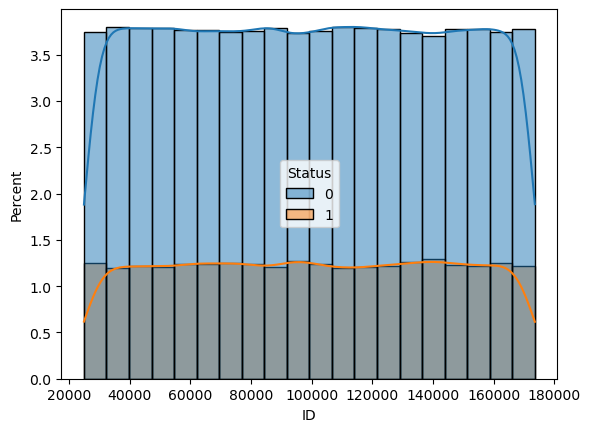

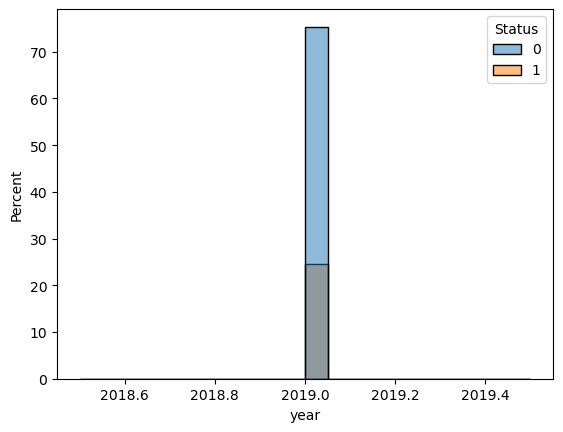

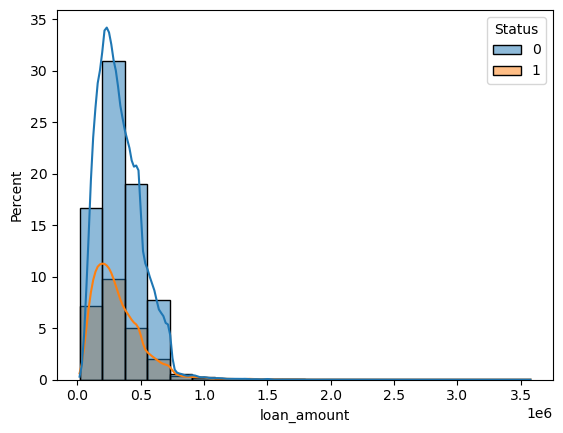

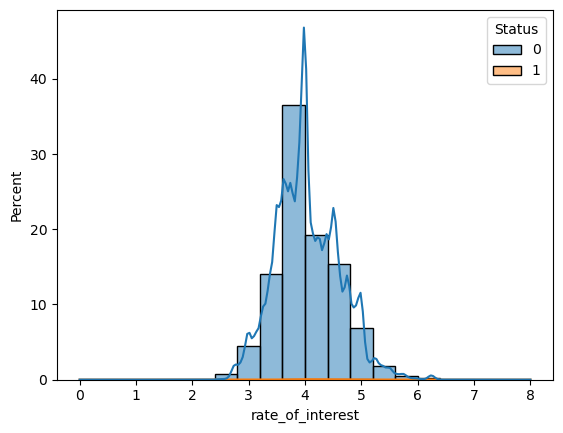

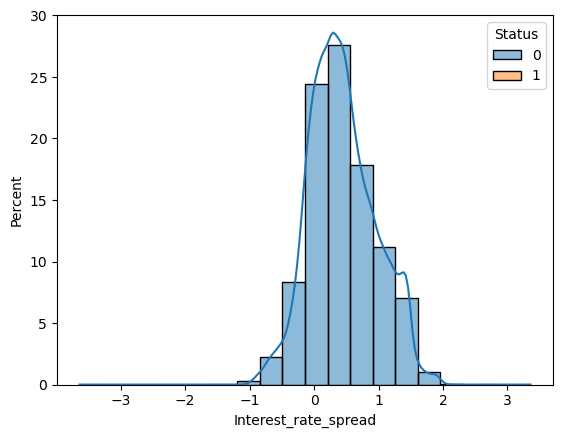

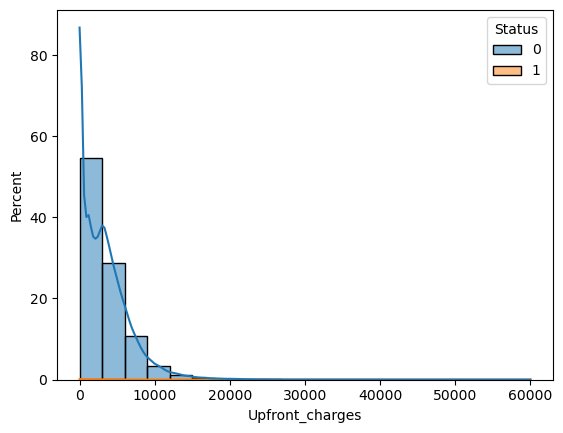

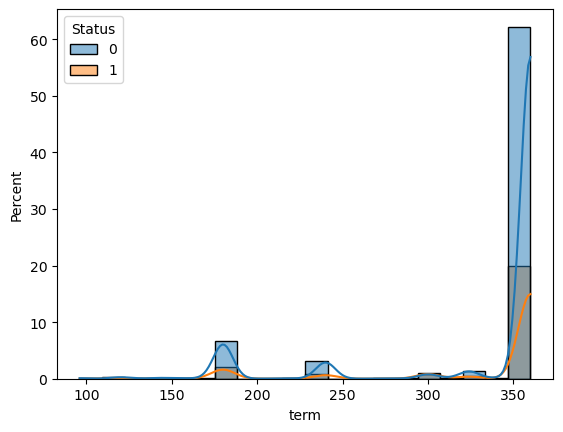

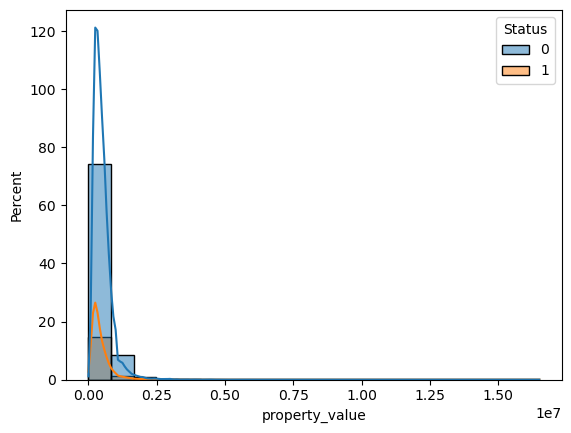

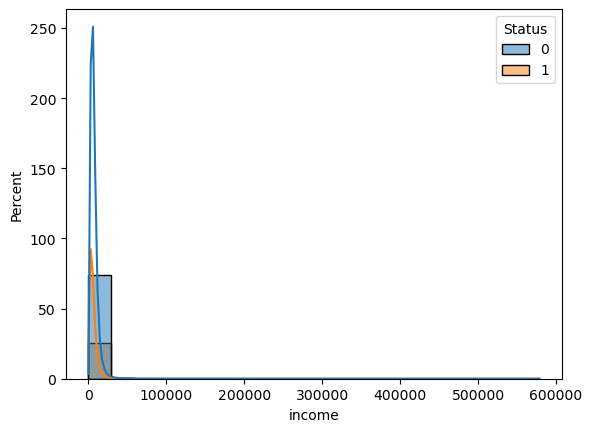

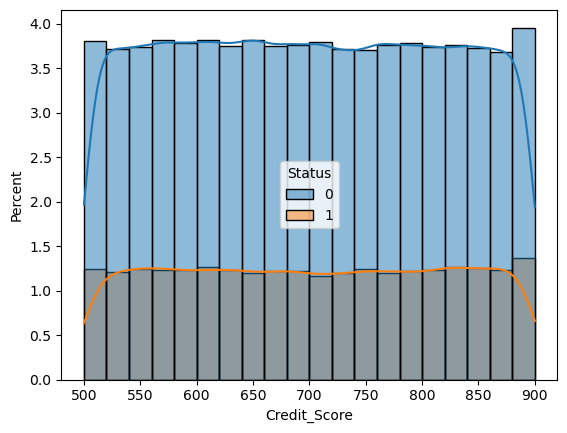

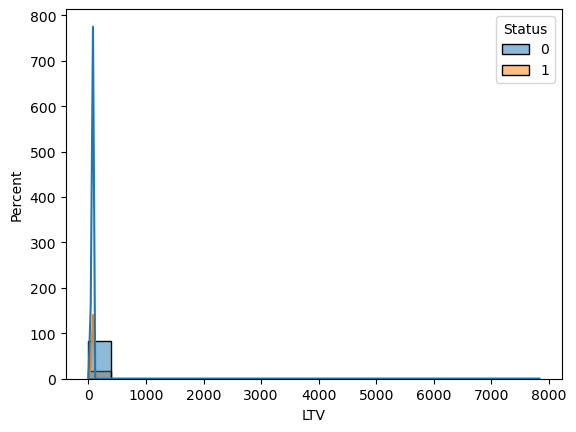

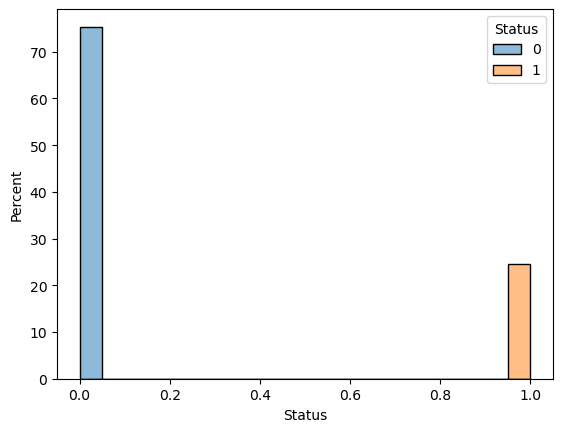

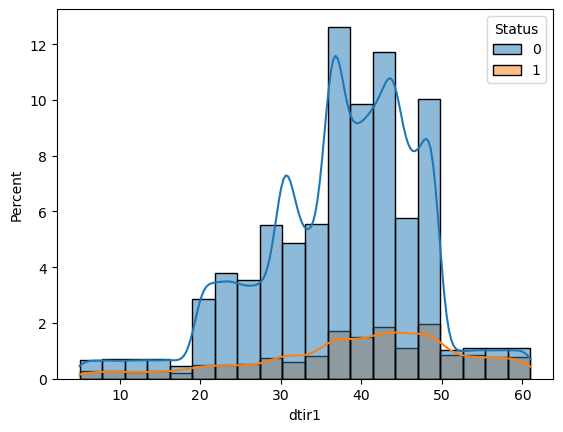

In [25]:
def hist_target_plotter(data, target):
    for col in data.select_dtypes("number"):
        sns.histplot(data=data, x=col, hue=target, stat="percent", kde=True, bins=20
                   )
        plt.show()
        
hist_target_plotter(loan_df, "Status")

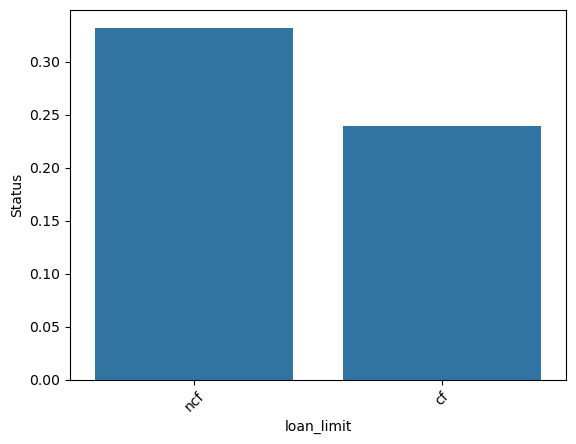

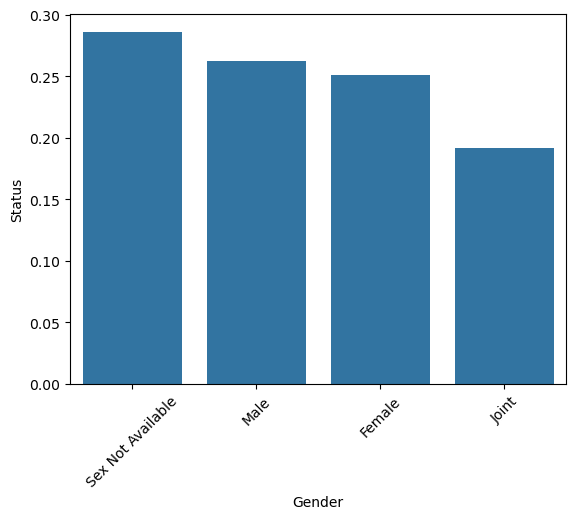

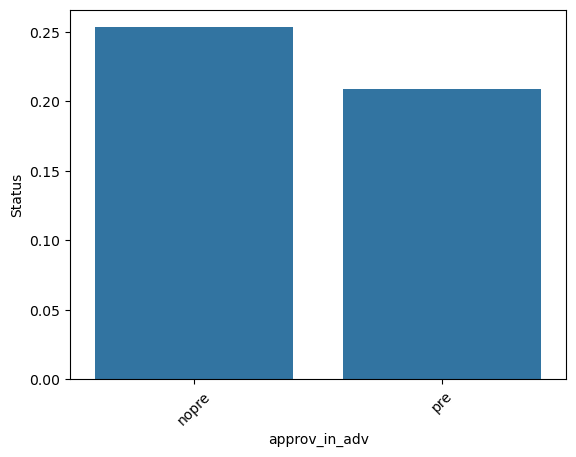

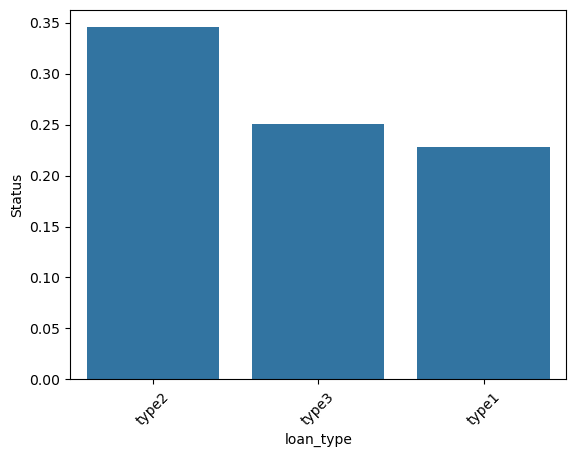

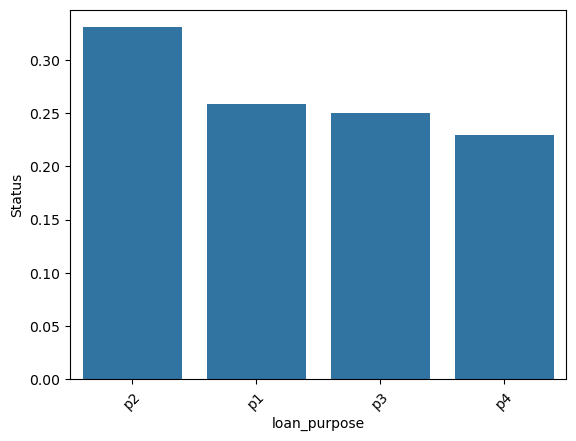

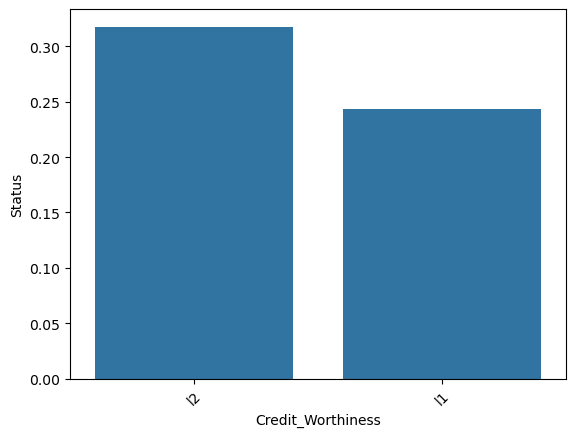

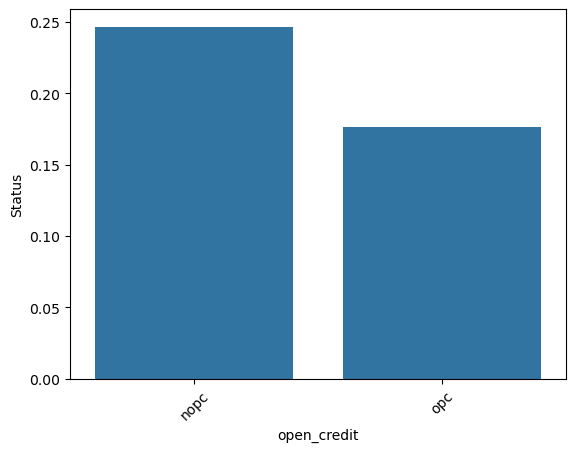

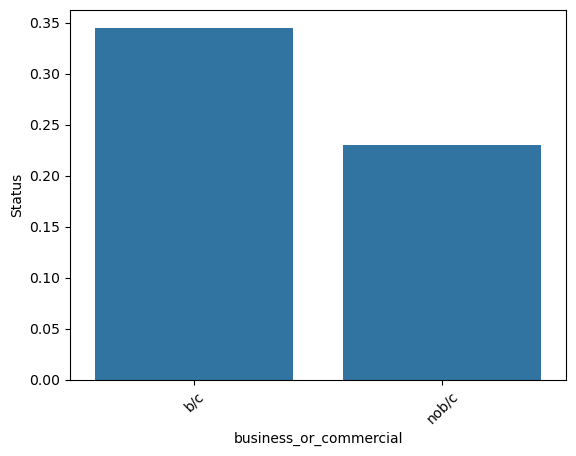

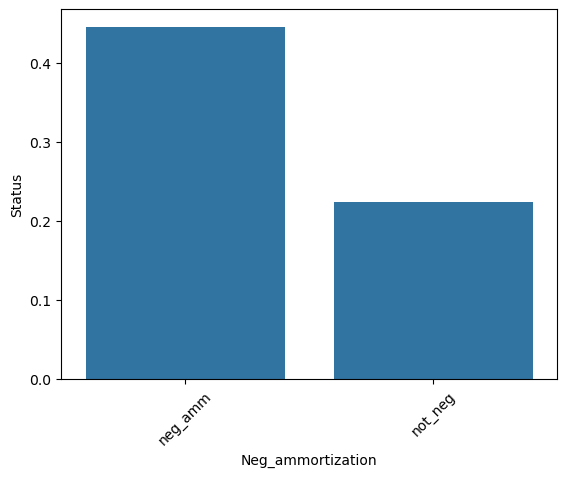

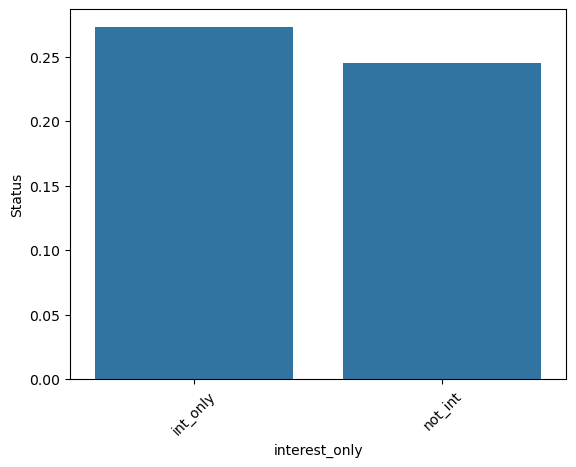

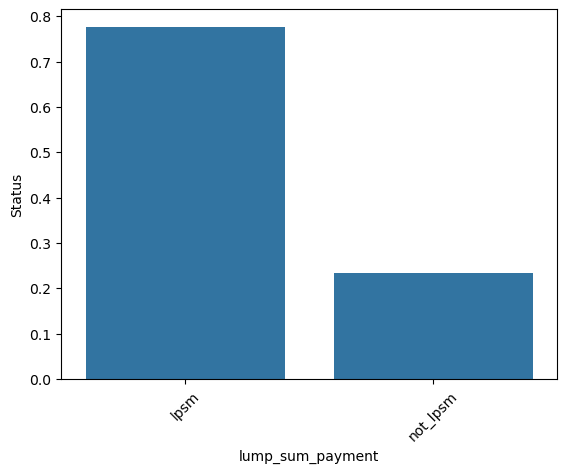

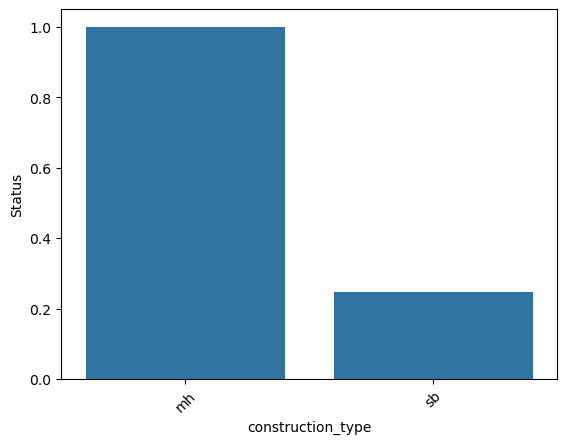

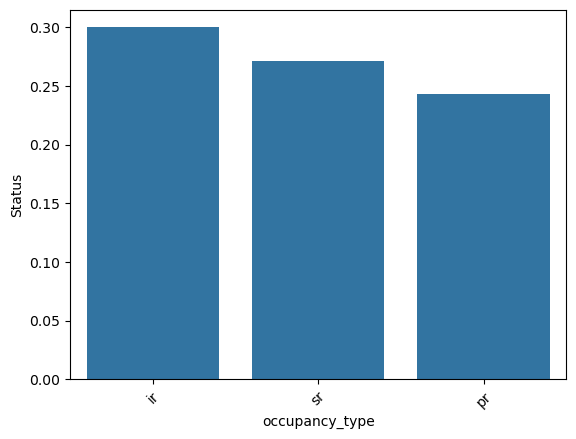

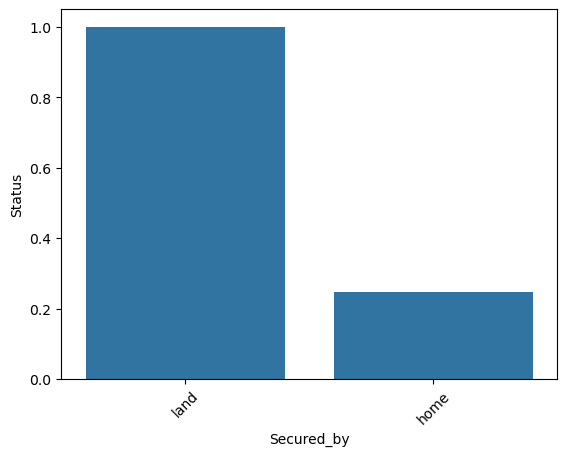

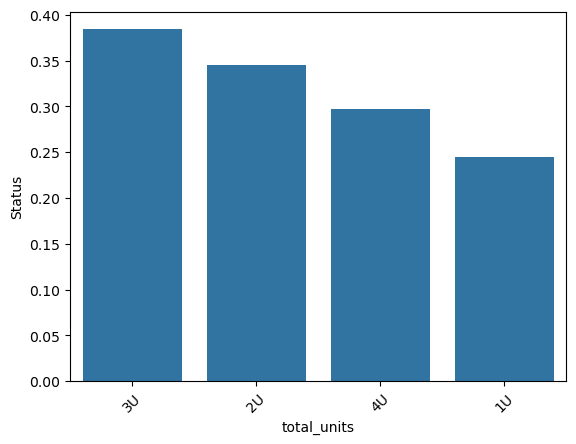

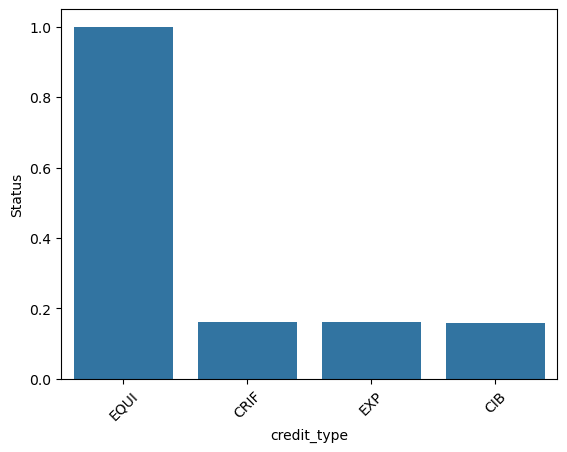

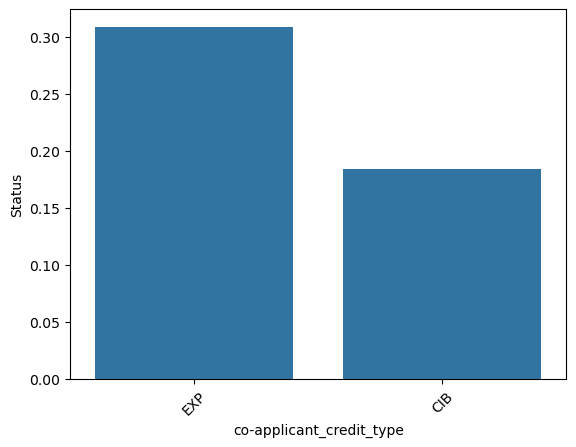

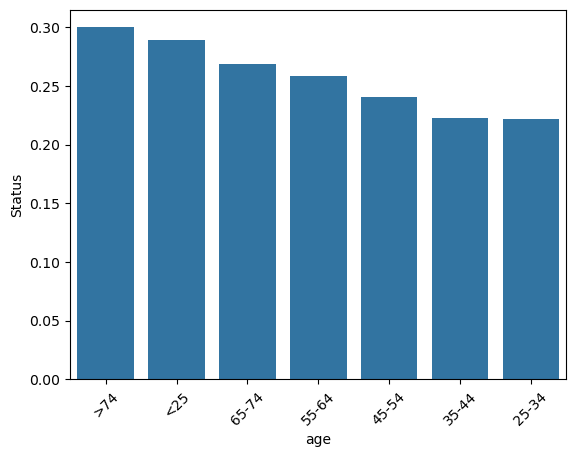

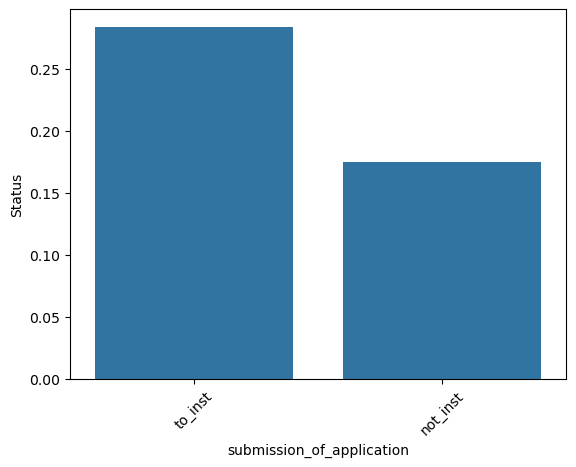

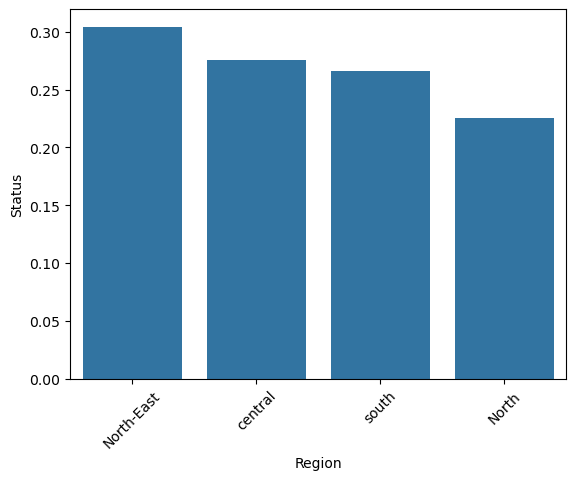

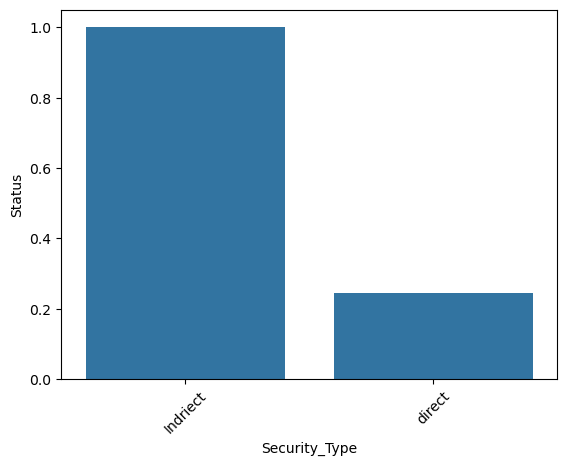

In [26]:
def cat_plotter(data, target):
    for col in data.select_dtypes(["object"]).columns:
        sns.barplot(
            data=(
                data
                .groupby(col, as_index=False)
                .agg({target: "mean"})
                .sort_values(by=target, ascending=False)
                 ), 
            x=col, 
            y=target)
        plt.xticks(rotation=45)
        plt.show()
        
cat_plotter(loan_df, "Status")

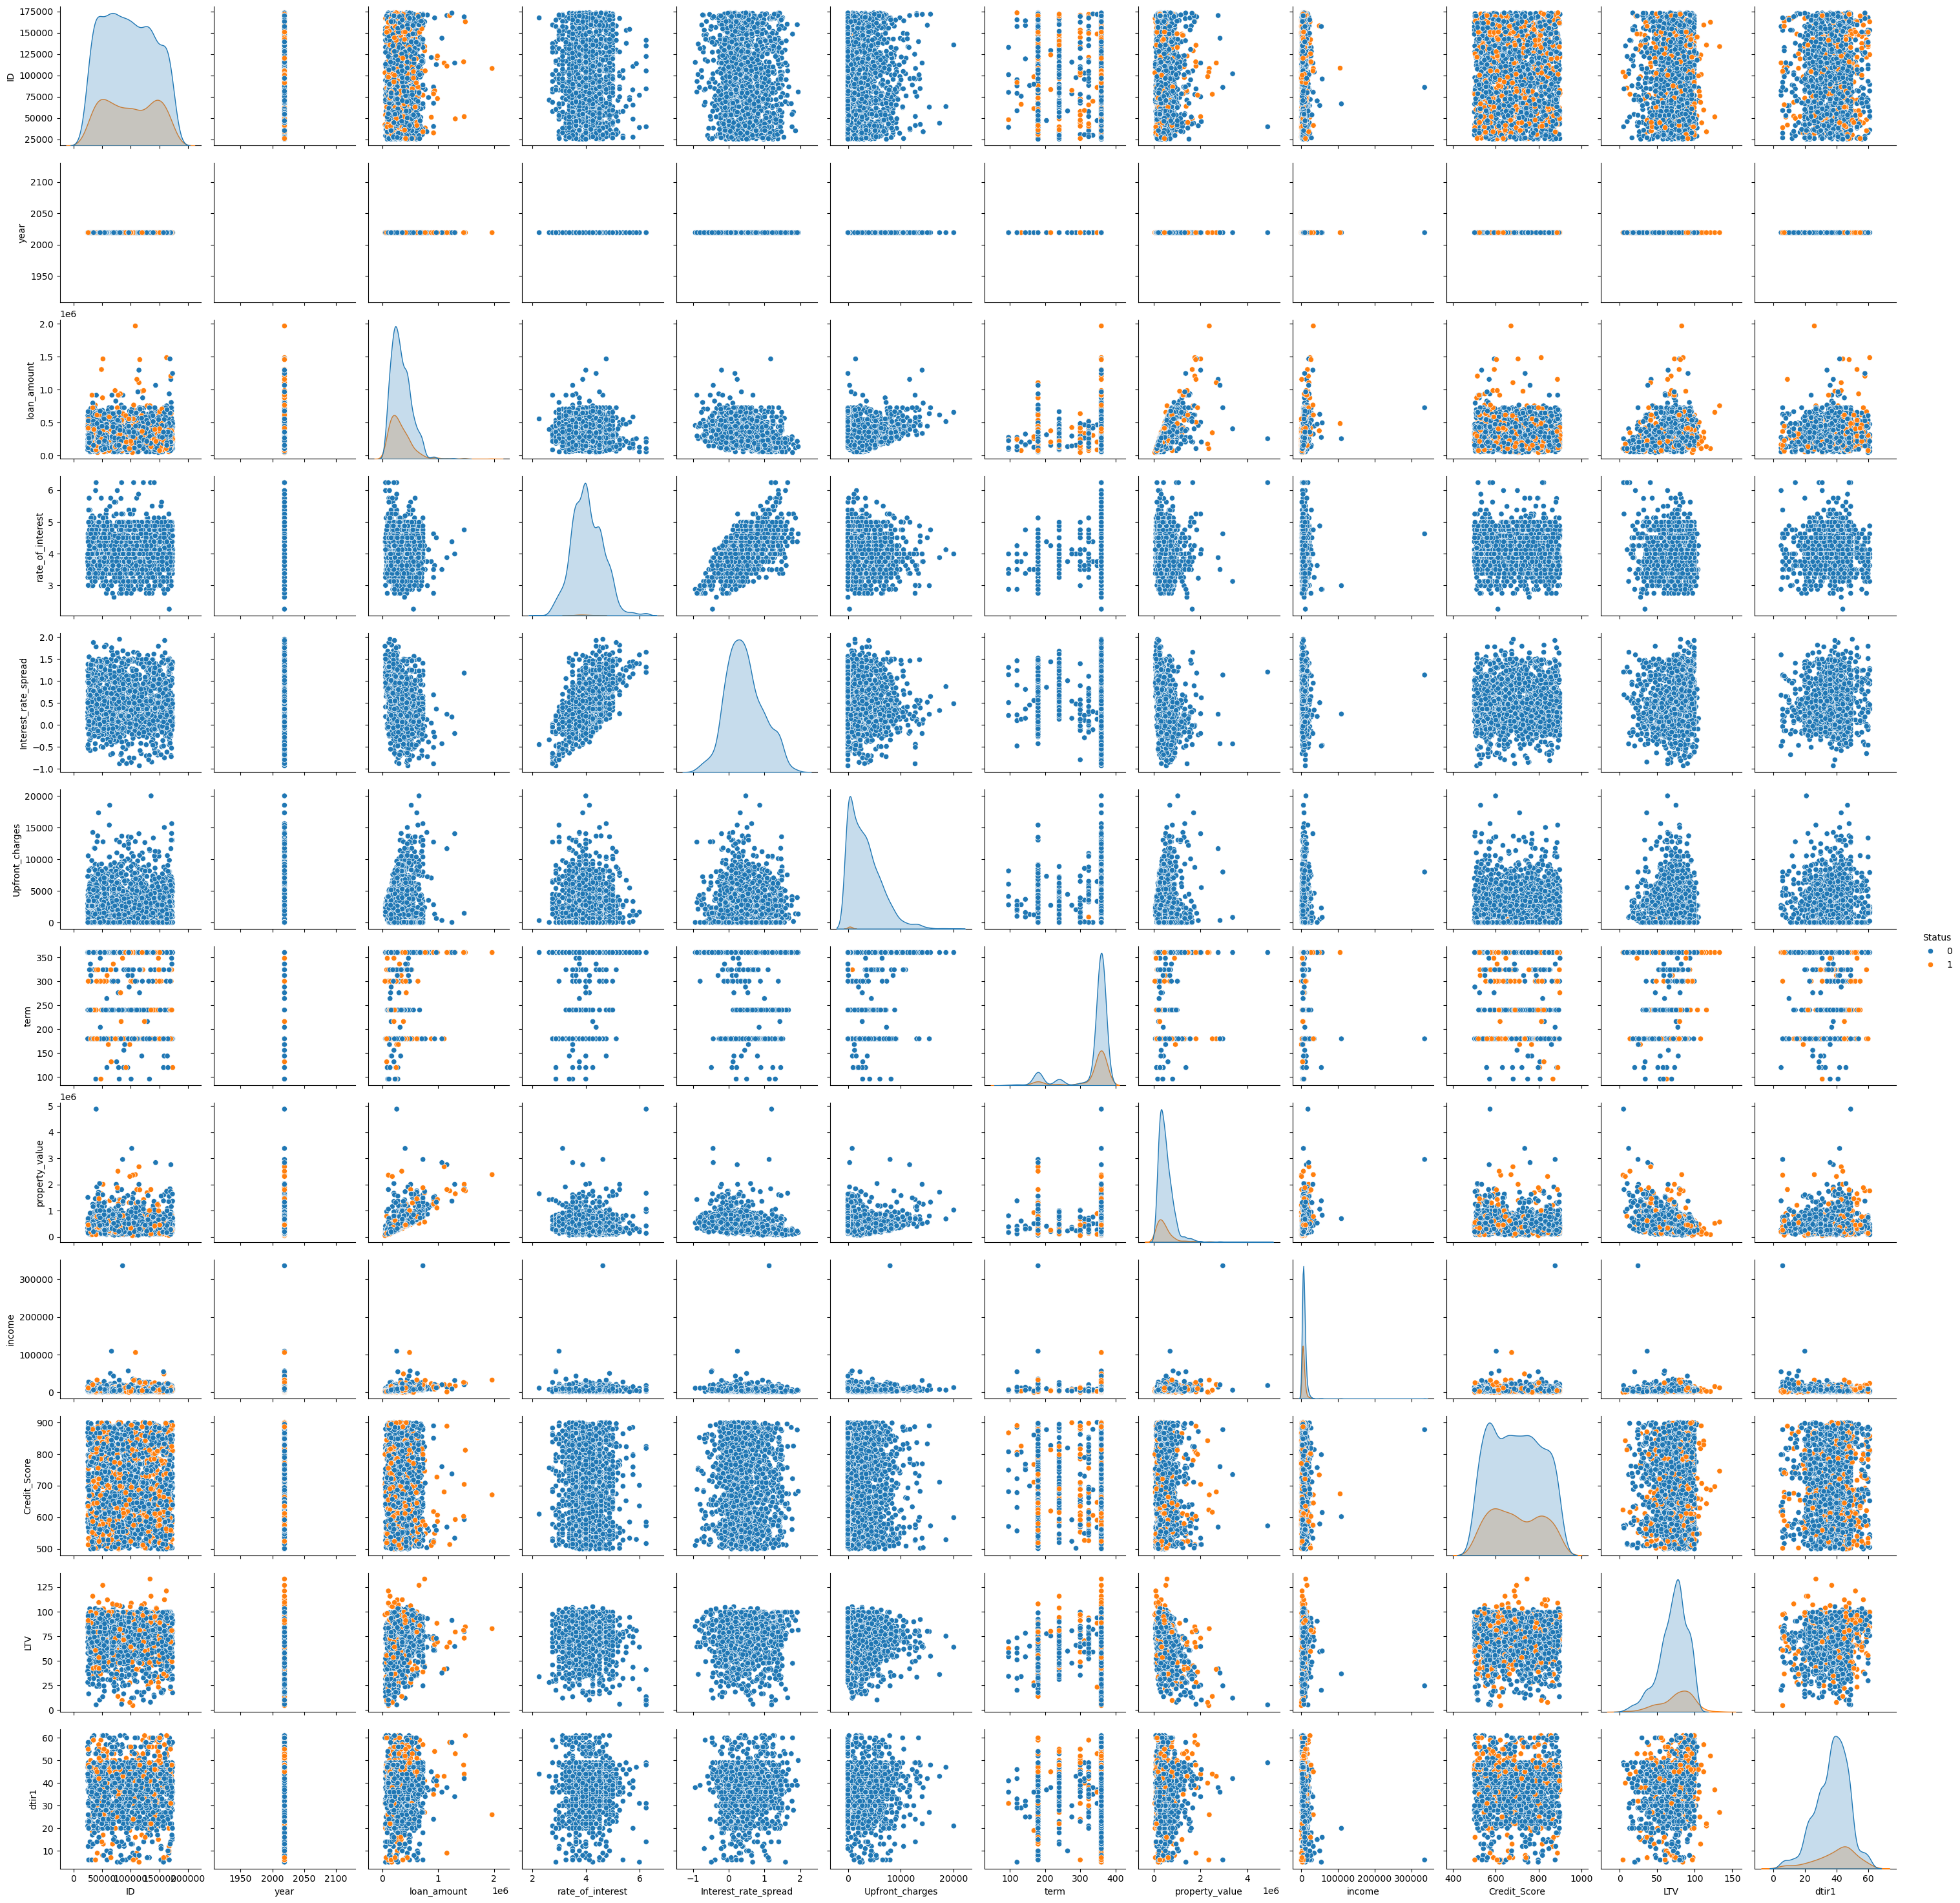

In [27]:
sns.pairplot(loan_df.sample(2000), hue="Status")

<Axes: xlabel='loan_amount', ylabel='income'>

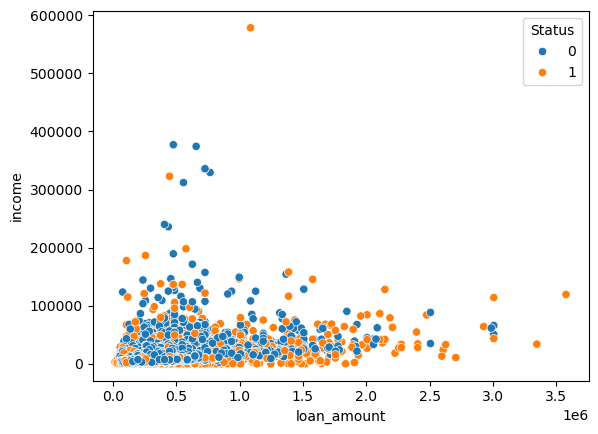

In [28]:
sns.scatterplot(loan_df, x="loan_amount", y="income", hue="Status" )

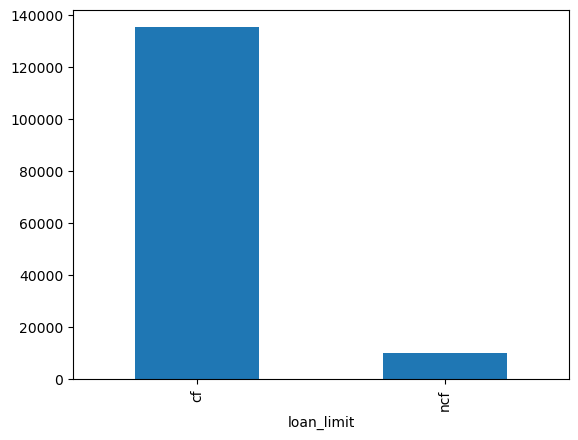

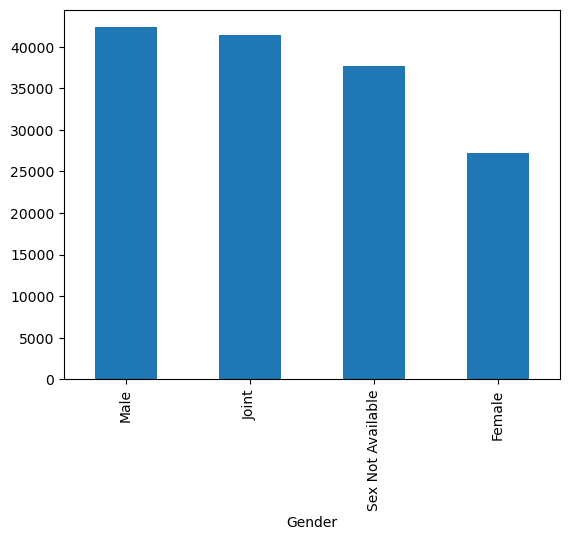

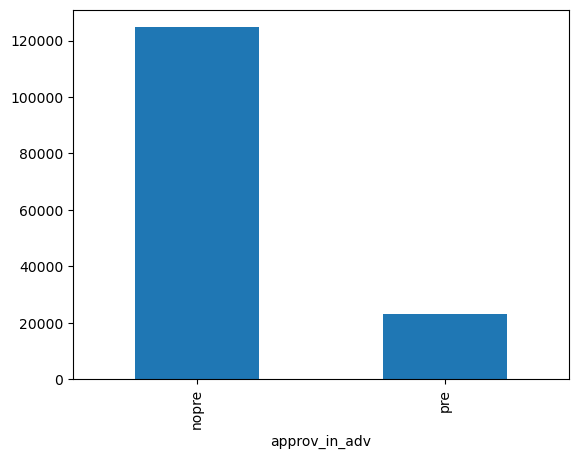

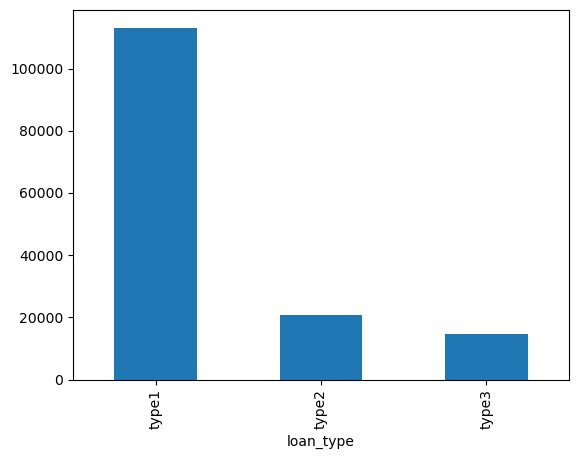

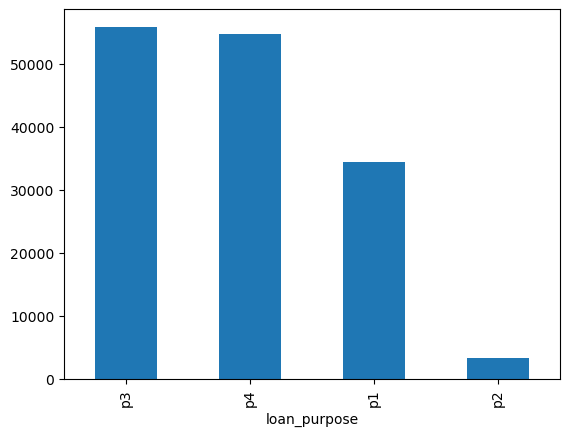

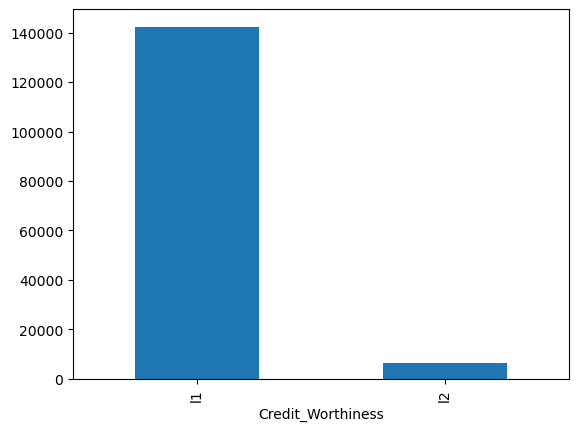

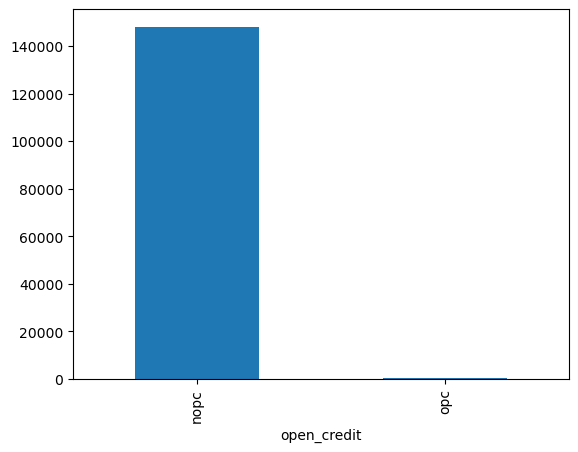

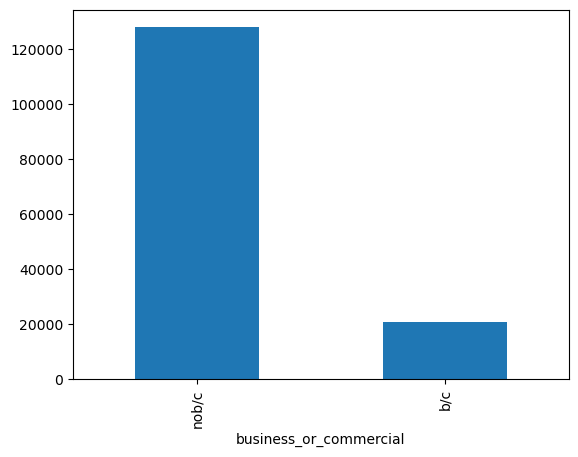

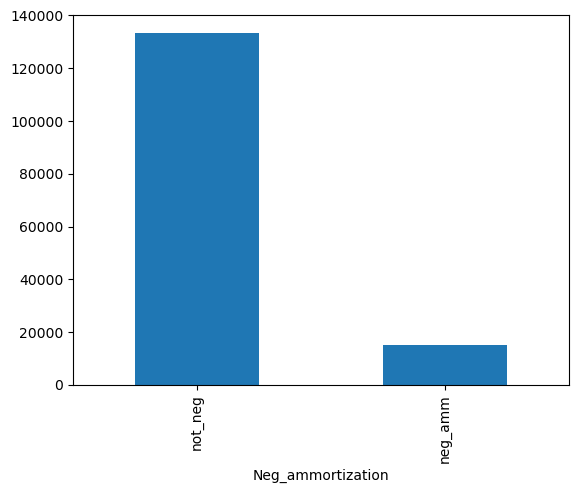

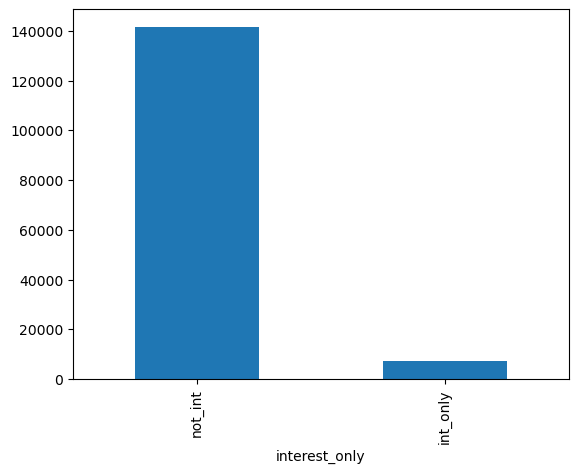

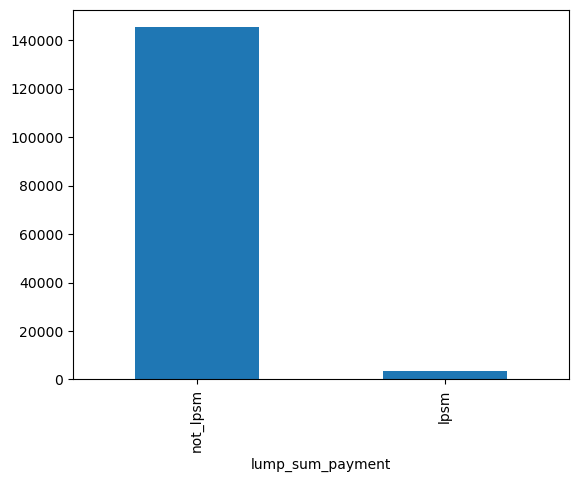

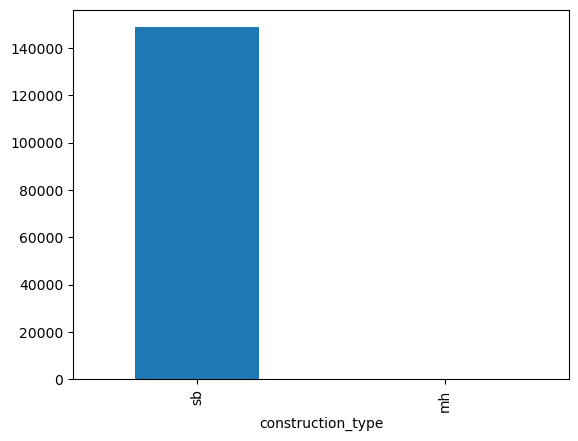

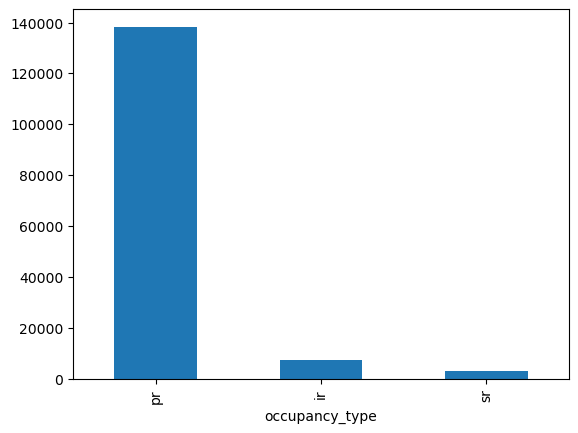

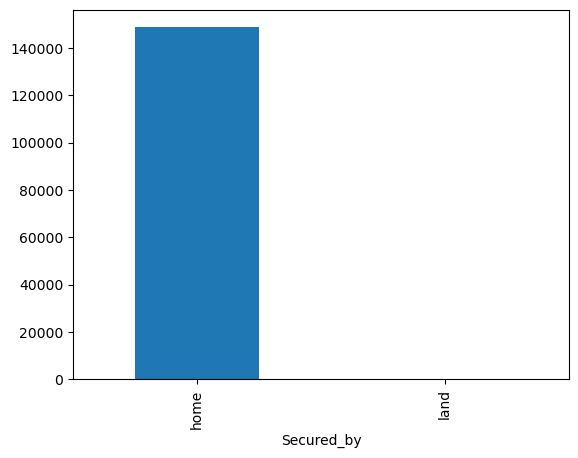

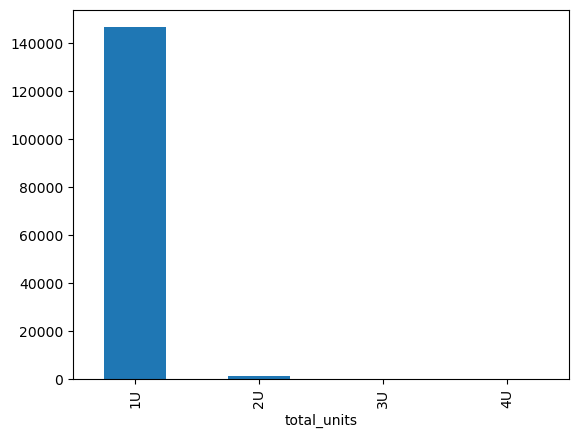

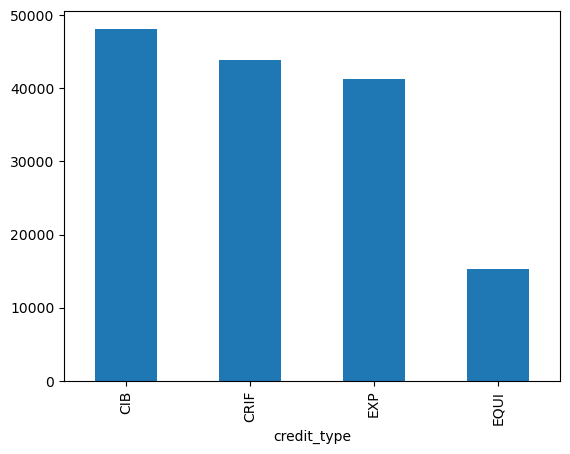

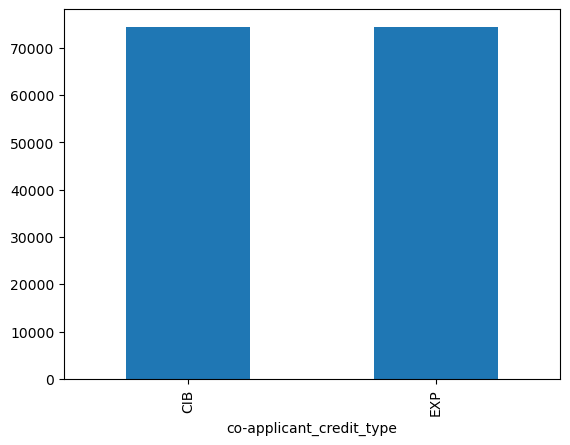

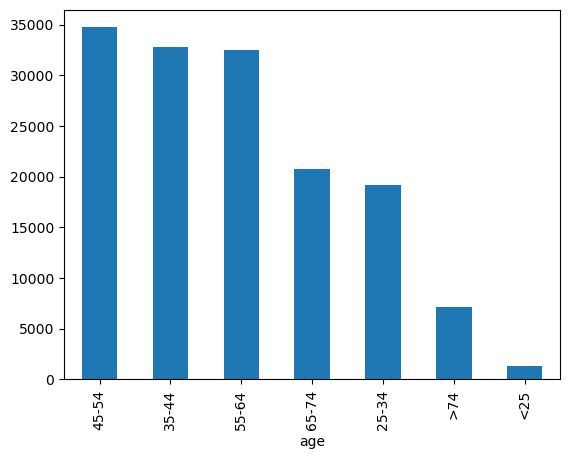

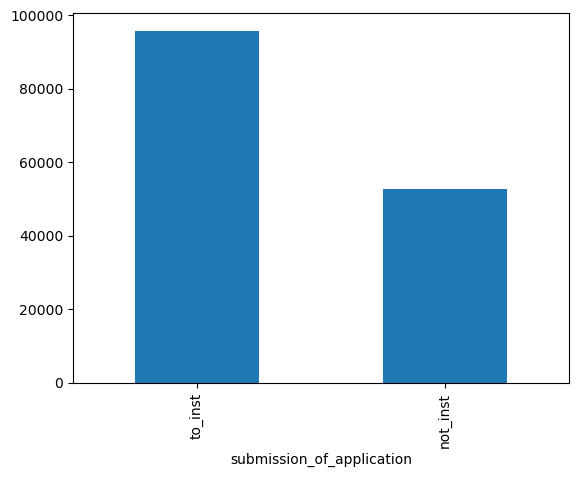

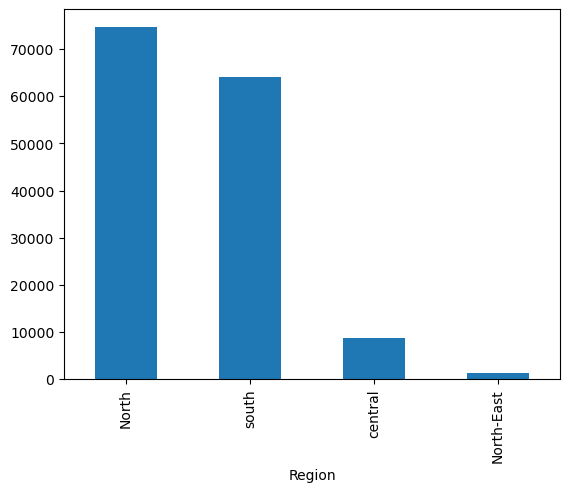

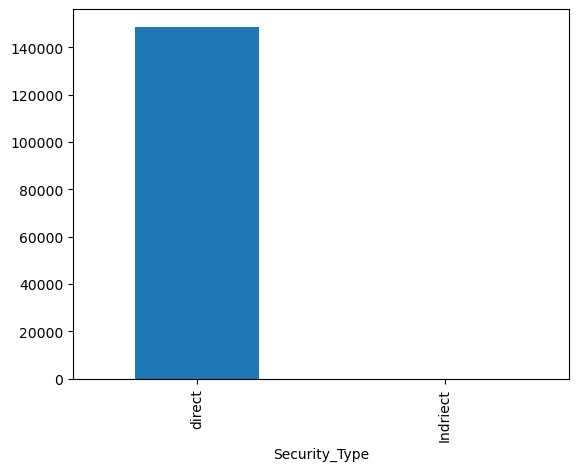

In [29]:
for column in loan_df.select_dtypes("object").columns:
    loan_df[column].value_counts(normalize=False).plot.bar()
    plt.show()

## Feature Engineering

In [30]:
loan_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 148670 entries, 0 to 148669
Data columns (total 34 columns):
 #   Column                     Non-Null Count   Dtype  
---  ------                     --------------   -----  
 0   ID                         148670 non-null  int64  
 1   year                       148670 non-null  int64  
 2   loan_limit                 145326 non-null  object 
 3   Gender                     148670 non-null  object 
 4   approv_in_adv              147762 non-null  object 
 5   loan_type                  148670 non-null  object 
 6   loan_purpose               148536 non-null  object 
 7   Credit_Worthiness          148670 non-null  object 
 8   open_credit                148670 non-null  object 
 9   business_or_commercial     148670 non-null  object 
 10  loan_amount                148670 non-null  int64  
 11  rate_of_interest           112231 non-null  float64
 12  Interest_rate_spread       112031 non-null  float64
 13  Upfront_charges            10

In [31]:
(loan_df[["Credit_Score", "loan_amount"]] 
 - loan_df[["Credit_Score", "loan_amount"]].mean()) / loan_df[["Credit_Score", "loan_amount"]].std()

,Credit_Score,loan_amount
0,0.502356,-1.166976
1,-1.275409,-0.677604
2,1.158230,0.409888
3,-0.973362,0.681761
4,-0.843913,1.986752
...,...,...
148665,-0.352007,0.573012
148666,-1.128700,1.388631
148667,0.019080,0.627387
148668,0.321127,-0.731979


In [32]:
from sklearn.preprocessing import StandardScaler

std = StandardScaler()

std.fit_transform(loan_df[["Credit_Score", "loan_amount"]])

array([[ 0.50235739, -1.16697989],
       [-1.27541323, -0.6776066 ],
       [ 1.15823392,  0.40988958],
       ...,
       [ 0.01907994,  0.62738881],
       [ 0.32112834, -0.73198141],
       [ 1.12371411,  0.40988958]])

In [33]:
loan_df["total_units"].value_counts()

total_units
1U    146480
2U      1477
3U       393
4U       320
Name: count, dtype: int64

<Axes: xlabel='total_units', ylabel='Status'>

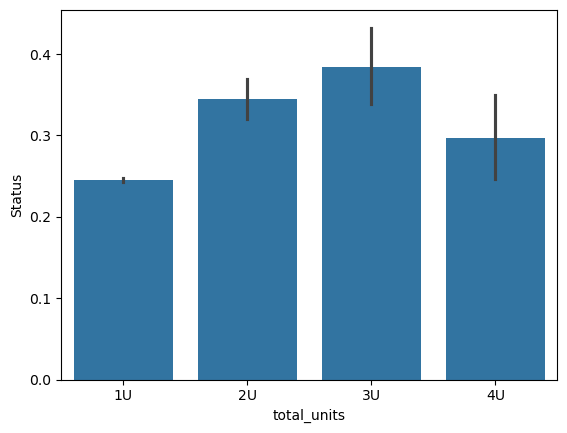

In [34]:
sns.barplot(loan_df, x="total_units", y="Status")

In [35]:
loan_df = loan_df.assign(
    total_units = loan_df["total_units"].map({
        "1U": "1U",
        "2U": "2U+",
        "3U": "2U+",
        "4U": "2U+"}),
    loan_amt_v_income = loan_df["loan_amount"]/loan_df["income"]
)

loan_df[["total_units", "loan_amt_v_income"]].head()

,total_units,loan_amt_v_income
0,1U,66.954023
1,1U,41.465863
2,1U,42.879747
3,1U,38.425926
4,1U,66.714559


<Axes: xlabel='total_units', ylabel='Status'>

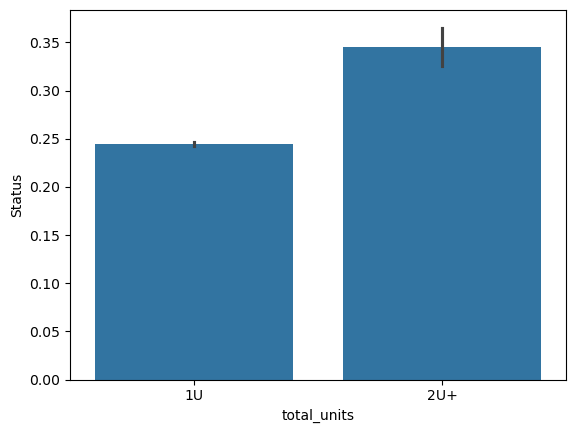

In [36]:
sns.barplot(loan_df, x="total_units", y="Status")

<Axes: xlabel='loan_amt_v_income', ylabel='Count'>

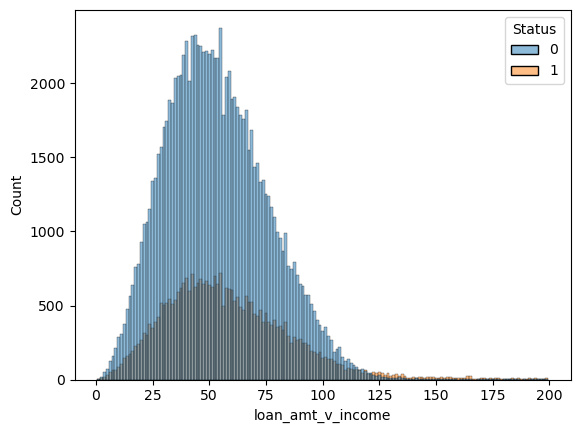

In [37]:
sns.histplot(
    loan_df.query("loan_amt_v_income < 200"), 
    hue="Status",
    x="loan_amt_v_income"
)

In [38]:
orders = pd.DataFrame({
    "Customer_ID": [10001, 10001, 10002, 10002, 10003, 10004],
    "Order_Date": ["2023-01-25", "2023-06-13", "2023-02-02", "2023-02-02", "2023-05-15", "2023-02-17"],
    "Product_ID": ["GPQ-123", "QP3-111", "GPQ-123", "ACD-489", "GPQ-123", "QP3-123"],
    "Item_Price": [59.99, 79.99, 59.99, 19.99, 59.99, 79.99],
    "Quantity": [3, 5, 1, 2, 1, 4],
}).astype({"Order_Date": "datetime64[ns]"})

orders.head()

,Customer_ID,Order_Date,Product_ID,Item_Price,Quantity
0,10001,2023-01-25,GPQ-123,59.99,3
1,10001,2023-06-13,QP3-111,79.99,5
2,10002,2023-02-02,GPQ-123,59.99,1
3,10002,2023-02-02,ACD-489,19.99,2
4,10003,2023-05-15,GPQ-123,59.99,1


In [39]:
orders = orders.assign(
    total_value = orders["Item_Price"] * orders["Quantity"],
    days_since_last_purchase = (pd.Timestamp.today() - orders["Order_Date"]).dt.days,
)

orders.head()

,Customer_ID,Order_Date,Product_ID,Item_Price,Quantity,total_value,days_since_last_purchase
0,10001,2023-01-25,GPQ-123,59.99,3,179.97,329
1,10001,2023-06-13,QP3-111,79.99,5,399.95,190
2,10002,2023-02-02,GPQ-123,59.99,1,59.99,321
3,10002,2023-02-02,ACD-489,19.99,2,39.98,321
4,10003,2023-05-15,GPQ-123,59.99,1,59.99,219


In [40]:
orders.groupby("Customer_ID").agg(
    total_items_sold = ("Quantity", "sum"),
    average_value = ("total_value", "mean")
)

,total_items_sold,average_value
Customer_ID,,
10001,8,289.960
10002,3,49.985
10003,1,59.990
10004,4,319.960


In [41]:
def add_deviation_feature(X, feature, category):
    
    # temp groupby object
    category_gb = X.groupby(category)[feature]
    
    # create columns of category means and standard deviations
    category_mean = category_gb.transform(lambda x: x.mean())
    category_std = category_gb.transform(lambda x: x.std())
    
    # compute stds from category mean for each feature value,
    # add to X as new feature
    deviation_feature = (X[feature] - category_mean) / category_std 
    X[feature + '_Dev_' + category] = deviation_feature


add_deviation_feature(loan_df, 'income', 'Region')

loan_df[["income", "Region", "income_Dev_Region"]].sample(20).sort_values("income")

,income,Region,income_Dev_Region
93592,840.0,North,-0.917308
100605,2640.0,south,-0.673752
135307,2760.0,south,-0.655228
35074,2760.0,south,-0.655228
33490,2880.0,North,-0.612915
13639,3480.0,south,-0.544083
49359,3720.0,central,-0.576572
1024,3720.0,North,-0.487577
84173,4980.0,south,-0.312531
3878,6960.0,North,-0.004129


## Data Prep

In [42]:
# Drop useless/unpromising columns

prep_loan_df = loan_df.drop([
    "year", 
     "ID", 
     "open_credit", 
    "construction_type", 
    "Security_Type", 
    "Secured_by"], 
    axis=1
)

prep_loan_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 148670 entries, 0 to 148669
Data columns (total 30 columns):
 #   Column                     Non-Null Count   Dtype  
---  ------                     --------------   -----  
 0   loan_limit                 145326 non-null  object 
 1   Gender                     148670 non-null  object 
 2   approv_in_adv              147762 non-null  object 
 3   loan_type                  148670 non-null  object 
 4   loan_purpose               148536 non-null  object 
 5   Credit_Worthiness          148670 non-null  object 
 6   business_or_commercial     148670 non-null  object 
 7   loan_amount                148670 non-null  int64  
 8   rate_of_interest           112231 non-null  float64
 9   Interest_rate_spread       112031 non-null  float64
 10  Upfront_charges            109028 non-null  float64
 11  term                       148629 non-null  float64
 12  Neg_ammortization          148549 non-null  object 
 13  interest_only              14

In [43]:
# data splitting

from sklearn.model_selection import train_test_split

X = pd.get_dummies(prep_loan_df[["loan_limit", "Gender", "loan_amount"]], drop_first=True)
y = prep_loan_df["Status"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=.2, random_state=2023)

print(f"Training Size: {X_train.shape[0]}, Test Size: {X_test.shape[0]}")

Training Size: 118936, Test Size: 29734


In [44]:
# feature scaling

from sklearn.preprocessing import StandardScaler

std = StandardScaler()

X_train_std = std.fit_transform(X_train)
X_test_std = std.transform(X_test)